# From AI that breaks to AI that is weaponised

Data: the AI Incident Database (AIID), export of 19 October 2026, with 1,749 incidents and 7,955 news reports.

**Questions**
1. Has the type of AI harm changed over time, from systems that fail to people who misuse them?
2. Who deploys and develops the systems involved, and who gets harmed?
3. What do the news reports focus on?
4. Which topics come out of the incident texts, and do different methods agree?
5. Can a model predict the type of harm from the description alone?

The AIID is a curated collection, not a full count of AI harm. A rise in incidents can also mean more media attention or more editor work, so all trends here are about *reported* incidents.

## 1. Setup

In [32]:
import re
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from IPython.display import display

In [33]:
DATA_FILE = Path("data/raw/AIID_Excel_Export-20261019.xlsx")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
SNAPSHOT = "19 Oct 2026"
SEED = 42

In [92]:
DOMAINS = ["Malicious use", "System failures", "Discrimination & toxicity", "Misinformation",
           "Privacy & security", "Human-computer interaction", "Socioeconomic & environmental"]

DOM_COLOR = {"Malicious use": "#CC3311",
             "System failures": "#0077BB",
             "Discrimination & toxicity": "#AA4499",
             "Misinformation": "#DDCC77",
             "Privacy & security": "#44AA99",
             "Human-computer interaction": "#999933",
             "Socioeconomic & environmental": "#332288",
             "Unclassified": "#DDDDDD"}

# light fills where white text is hard to read
DARK_TEXT = ["Misinformation", "Privacy & security", "Human-computer interaction", "Unclassified"]

INK = "#2B2B2B"
CMP_A, CMP_B = "#225555", "#A6A6A6"
HIGHLIGHT = "#CC3311"
SEQ = LinearSegmentedColormap.from_list("seq", ["#F4F4FA", "#332288"])

In [35]:
sns.set_theme(style="white")
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"],
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 200,
})

def titles(ax, title, sub=None):
    ax.set_title(title, pad=24 if sub else 10)
    if sub:
        ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=9.5, color="#5A5A5A", va="bottom")

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")

def domain_legend(ax, names=DOMAINS + ["Unclassified"], **kw):
    handles = [plt.Line2D([], [], marker="s", ls="", color=DOM_COLOR[n], markersize=10, label=n) for n in names]
    return ax.legend(handles=handles, **kw)

## 2. Data

The Excel export has five sheets. We use **Incidents** (one row per incident), **Reports** (one row per news article) and the **Data Dictionary** to check the fill rates. The Entities sheet only lists entity names with no link to incidents, so it is not loaded.

In [36]:
inc_raw = pd.read_excel(DATA_FILE, sheet_name="Incidents", header=2)
rep_raw = pd.read_excel(DATA_FILE, sheet_name="Reports", header=1)
data_dict = pd.read_excel(DATA_FILE, sheet_name="Data Dictionary", header=1)

print(f"Incidents: {inc_raw.shape[0]:,} rows, {inc_raw.shape[1]} columns")
print(f"Reports:   {rep_raw.shape[0]:,} rows, {rep_raw.shape[1]} columns")

Incidents: 1,749 rows, 59 columns
Reports:   7,955 rows, 12 columns


In [37]:
print("Incident ID unique:", inc_raw["Incident ID"].is_unique)
print("Dates from", inc_raw["date"].min().date(), "to", inc_raw["date"].max().date())
display(data_dict["Group"].value_counts().to_frame("columns"))
display(inc_raw[["Incident ID", "date", "title", "deployer", "developer", "harmed", "Risk Domain", "Intent"]].head(3))

Incident ID unique: True
Dates from 1983-09-26 to 2026-10-07


,columns
Group,
CSETv1,35
Identity,12
MIT,5
GMF,5
Coverage,2


,Incident ID,date,title,deployer,developer,harmed,Risk Domain,Intent
0,1,2015-05-19,Google’s YouTube Kids App Presents Inappropria...,Youtube,Youtube,Minors,Discrimination and Toxicity,Unintentional
1,2,2018-12-05,Warehouse robot ruptures can of bear spray and...,Amazon,Amazon,Warehouse Workers,"AI system safety, failures, and limitations",Unintentional
2,3,2018-10-27,Crashes with Maneuvering Characteristics Augme...,Boeing,Boeing,"Airplane Passengers, Airplane Crew","AI system safety, failures, and limitations",Unintentional


### 2.1 Missing values

Some columns are not really blank when they are empty: they contain `[]`.

In [38]:
empty_lists = (inc_raw.astype(str) == "[]").sum()
empty_lists[empty_lists > 0].sort_values(ascending=False).to_frame("cells with []")

,cells with []
Infrastructure Sectors,152
AI Methods,12
AI Task,12
Harm Distribution Basis,9
Sector of Deployment,6


In [39]:
def empty_share(df):
    empty = df.isna() | df.astype(str).apply(lambda s: s.str.strip().isin(["", "[]"]))
    return (empty.mean() * 100).round(1)

fill = data_dict.set_index("Column")[["Group", "Fill Rate"]]
fill["dictionary %"] = fill["Fill Rate"].str.rstrip("%").astype(float)
fill["actual %"] = 100 - empty_share(inc_raw)

display(fill.groupby("Group", sort=False)["actual %"].agg(["count", "min", "median", "max"]).round(0))
print("Columns where the dictionary is off by 2 points or more:")
display(fill.loc[(fill["actual %"] - fill["dictionary %"]).abs() >= 2, ["Group", "dictionary %", "actual %"]])

,count,min,median,max
Group,,,,
Identity,12,30.0,100.0,100.0
Coverage,2,86.0,93.0,100.0
MIT,5,86.0,86.0,86.0
GMF,5,2.0,2.0,2.0
CSETv1,35,3.0,11.0,12.0


Columns where the dictionary is off by 2 points or more:


,Group,dictionary %,actual %
Column,,,
Implicated Systems,Identity,100.0,68.6
Editor Notes,Identity,100.0,30.4
Data Sources,Coverage,100.0,85.5
Infrastructure Sectors,CSETv1,12.0,3.1
Country Code,CSETv1,12.0,8.0
Incident Month,CSETv1,12.0,8.2
Incident Day,CSETv1,12.0,4.2
AI Task,CSETv1,12.0,9.6
AI Methods,CSETv1,12.0,5.2


In [40]:
empty_share(rep_raw).to_frame("empty %")

,empty %
Report Number,0.0
Title,10.2
URL,10.2
Source Domain,10.2
Date Published,0.0
Date Downloaded,0.0
Authors,10.2
Submitters,0.0
Language,0.0
Tags,79.5


The basic fields (title, description, deployer, developer, harmed) are complete. The MIT risk taxonomy covers 86% of incidents, CSET about 11% and GMF only 1-2%, so the analysis is built on the MIT fields.

The Data Dictionary fill rates are not always right. It says 100% for *Implicated Systems*, *Editor Notes* and *Data Sources*, but they are filled for 69%, 30% and 86% of incidents. Several CSET columns also drop when `[]` is counted as empty (e.g. *Infrastructure Sectors* from 12% to 3%). We use our own numbers.

In the reports, about 10% have no title, URL, source or authors; these are checked in the report cleaning section.

### 2.2 Risk domains

The MIT taxonomy puts each incident in one of seven risk domains. Two of them are much smaller than the rest.

In [41]:
dom = inc_raw["Risk Domain"].fillna("Not classified").value_counts().to_frame("incidents")
dom["% of all"] = (dom["incidents"] / len(inc_raw) * 100).round(1)
display(dom)

small = inc_raw[inc_raw["Risk Domain"].isin(["Human-Computer Interaction", "Socioeconomic & Environmental Harms"])]
pd.crosstab(small["Risk Subdomain"], small["Risk Domain"])

,incidents,% of all
Risk Domain,,
Malicious Actors & Misuse,566,32.4
"AI system safety, failures, and limitations",313,17.9
Not classified,253,14.5
Discrimination and Toxicity,243,13.9
Misinformation,196,11.2
Privacy & Security,112,6.4
Human-Computer Interaction,42,2.4
Socioeconomic & Environmental Harms,24,1.4


Risk Domain,Human-Computer Interaction,Socioeconomic & Environmental Harms
Risk Subdomain,,
Competitive dynamics,0,3
Economic and cultural devaluation of human effort,0,5
Environmental harm,0,1
Governance failure,0,3
Increased inequality and decline in employment quality,0,6
Loss of human agency and autonomy,4,0
Overreliance and unsafe use,38,0
Power centralization and unfair distribution of benefits,0,6


The two small domains are about different things (over-reliance on AI vs. jobs, power and the environment), so merging them into "Other" would mix unrelated topics. We keep all seven domains.

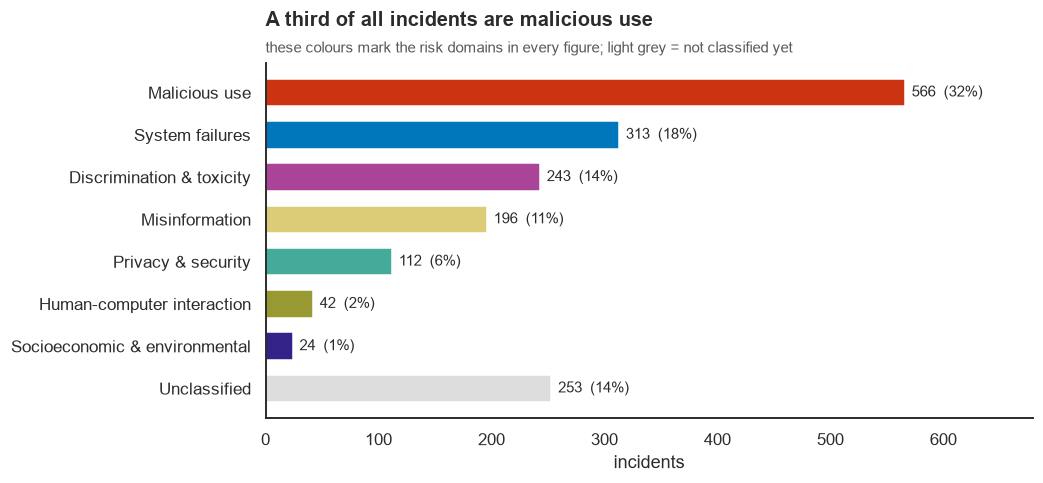

In [42]:
DOMAIN_MAP = {"Malicious Actors & Misuse": "Malicious use",
              "AI system safety, failures, and limitations": "System failures",
              "Discrimination and Toxicity": "Discrimination & toxicity",
              "Misinformation": "Misinformation",
              "Privacy & Security": "Privacy & security",
              "Human-Computer Interaction": "Human-computer interaction",
              "Socioeconomic & Environmental Harms": "Socioeconomic & environmental"}

domain = inc_raw["Risk Domain"].map(DOMAIN_MAP).fillna("Unclassified")
counts = domain.value_counts().reindex(DOMAINS + ["Unclassified"])[::-1]

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(counts.index, counts.values, color=[DOM_COLOR[d] for d in counts.index], height=0.65)
for y, v in enumerate(counts.values):
    ax.text(v + 6, y, f"{v}  ({v / len(inc_raw):.0%})", va="center", fontsize=10)
ax.set_xlim(0, counts.max() * 1.2)
ax.set_xlabel("incidents")
titles(ax, "A third of all incidents are malicious use",
       "these colours mark the risk domains in every figure; light grey = not classified yet")
save(fig, "00a_risk_domains")
plt.show()

In [43]:
unclassified = inc_raw["Risk Domain"].isna()
unclassified.groupby(inc_raw["year"] >= 2025).agg(["sum", "mean"]).rename(index={False: "before 2025", True: "2025-26"})

,sum,mean
year,,
before 2025,36,0.035225
2025-26,217,0.298487


253 incidents (14%) have no risk domain yet, and 86% of them are from 2025-26 (30% of that period vs 4% before).

### 2.3 Intent

The MIT taxonomy also records whether the harm was intentional. Besides *Intentional* and *Unintentional* there is a small *Other* group.

In [45]:
display(inc_raw["Intent"].value_counts(dropna=False).to_frame("incidents"))
print("Other incidents are often unclassified, and include a wide range of cases:")
inc_raw.loc[inc_raw["Intent"] == "Other", ["Risk Domain", "title"]].head(10)

,incidents
Intent,
Unintentional,740
Intentional,735
NaN,253
Other,21


Other incidents are often unclassified, and include a wide range of cases:


,Risk Domain,title
14,Discrimination and Toxicity,Amazon Censors Gay Books
20,"AI system safety, failures, and limitations",Tougher Turing Test Exposes Chatbots’ Stupidit...
41,Socioeconomic & Environmental Harms,Inefficiencies in the United States Resident M...
61,"AI system safety, failures, and limitations",Bad AI-Written Christmas Carols
84,"AI system safety, failures, and limitations","AI attempts to ease fear of robots, blurts out..."
155,"AI system safety, failures, and limitations",Tesla Autopilot’s Lane Recognition Allegedly V...
280,"AI system safety, failures, and limitations",OpenAI’s GPT-3 Reported as Unviable in Medical...
291,"AI system safety, failures, and limitations",Student-Developed Facial Recognition App Raise...
643,Privacy & Security,Alleged ChatGPT Account Compromise Reportedly ...
683,Malicious Actors & Misuse,Purported Deepfake Image Allegedly Circulating...


The 21 *Other* incidents are a mix of everything (bad chatbot answers, deepfakes, data leaks), so they don't form a third type of intent. They are left out of the intent analysis only; everywhere else they stay in.

In [46]:
INTENTS = ["Intentional", "Unintentional"]
inc_raw["Intent"].where(inc_raw["Intent"].isin(INTENTS)).value_counts(dropna=False)

Intent
Unintentional    740
Intentional      735
NaN              274
Name: count, dtype: int64

### 2.4 Years and periods

Most years before 2015 have only a few incidents, and 2026 stops in October.

In [47]:
per_year = inc_raw["year"].value_counts().sort_index()
print("Years before 2012:", per_year[per_year.index < 2012].sum(), "incidents in total")
print("Last date in 2026:", inc_raw.loc[inc_raw["year"] == 2026, "date"].max().date())
per_year[per_year.index >= 2012].to_frame("incidents").T

Years before 2012: 20 incidents in total
Last date in 2026: 2026-10-07


year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
incidents,8,6,13,24,41,50,46,45,91,80,109,179,310,460,267


In [48]:
PERIODS = ["up to 2018", "2019-22", "2023-24", "2025-26"]
period = pd.cut(inc_raw["year"], [0, 2018, 2022, 2024, 2026], labels=PERIODS)
period.value_counts().reindex(PERIODS).to_frame("incidents").T

year,up to 2018,2019-22,2023-24,2025-26
incidents,208,325,489,727


Single years are fine for counts, but shares need larger groups, so we also use four periods. The early years are merged into *up to 2018* because they are too small on their own, and 2023-24 and 2025-26 are two years each. 2026 is only partial (until 7 October), so it is shown hatched or marked in the yearly charts.

### 2.5 Entities: deployer, developer, harmed

These fields are lists of names written as one text, separated by commas. Before counting "who" appears most often we check three things: unknown values, the same name written in different ways, and companies that changed their name.

In [49]:
def tokens(s):
    return [] if pd.isna(s) else [t.strip() for t in str(s).split(",") if t.strip()]

FIELDS = ["deployer", "developer", "harmed"]
mentions = {f: inc_raw[f].map(tokens).explode().dropna() for f in FIELDS}

pd.DataFrame({
    "mentions": {f: len(m) for f, m in mentions.items()},
    "different names": {f: m.nunique() for f, m in mentions.items()},
    "exactly 'Unknown'": {f: (m.str.lower() == "unknown").sum() for f, m in mentions.items()},
    "'Unknown ...' variants": {f: m[m.str.lower().str.startswith("unknown ")].nunique() for f, m in mentions.items()},
})

,mentions,different names,exactly 'Unknown','Unknown ...' variants
deployer,3887,2021,25,137
developer,3111,732,80,27
harmed,7468,3791,4,1


In [50]:
actors = pd.concat([mentions["deployer"], mentions["developer"]])
actors[actors.str.lower().str.startswith("unknown")].value_counts().head(10).to_frame("mentions")

,mentions
Unknown,105
Unknown Actors,21
Unknown Ai Developers,10
Unknown Malicious Actors,9
Unknown Tiktok User,4
Unknown Social Media Account Operators,4
Unknown Social Media Accounts,3
Unknown Sextortionists,3
Unknown Cryptocurrency Scammers,3
Unknown Scammers Impersonating Elon Musk,3


#### Spelling mistakes

In [51]:
key = actors.str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
variants = actors.groupby(key).agg(lambda s: dict(s.value_counts()))
variants[variants.map(len) > 1].to_frame("written as")

,written as
does125,"{'Does 125': 1, 'Does 1 25': 1}"
perplexityai,"{'Perplexity Ai': 8, 'Perplexity.Ai': 1}"


#### Similarity between names

In [52]:
from sklearn.feature_extraction.text import TfidfVectorizer

freq = actors.value_counts()
names = freq[freq >= 5].index.tolist()
X = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5)).fit_transform(names)
sim = (X @ X.T).toarray()

pairs = [(sim[i, j], names[i], names[j]) for i in range(len(names)) for j in range(i + 1, len(names))]
pd.DataFrame(sorted(pairs, reverse=True)[:20], columns=["similarity", "name A", "name B"]).round(2)

,similarity,name A,name B
0,0.98,Software Developers,Ai Software Developers
1,0.98,Perplexity,Perplexity Ai
2,0.92,Synthetic Audio Generation Technology Developers,Synthetic Audio Generation Technology
3,0.92,Synthetic Image Generation Technology Developers,Synthetic Image Generation Technology
4,0.88,X (Twitter),X (Twitter) Users
5,0.86,Information Manipulation Actors,Information Manipulation Actors In Kosovo
6,0.84,Information Manipulation Actors,Pro Russian Information Manipulation Actors
7,0.84,Chatgpt,Chatgpt Users
8,0.84,Russian Government,Government Of Russia
9,0.83,Synthetic Media Generation Technology Developers,Synthetic Image Generation Technology Developers


#### Renamed entities throughout time

In [53]:
renamed = inc_raw.assign(name=inc_raw["deployer"].map(tokens) + inc_raw["developer"].map(tokens)).explode("name", ignore_index=True)
renamed = renamed[renamed["name"].isin(["Facebook", "Meta", "Twitter", "X (Twitter)"])]
pd.crosstab(renamed["year"].clip(lower=2016), renamed["name"]).rename(index={2016: "up to 2016"})

name,Facebook,Meta,Twitter,X (Twitter)
year,,,,
up to 2016,15,1,2,0
2017,6,2,0,0
2018,10,2,0,0
2019,6,4,0,0
2020,24,2,4,0
2021,23,5,6,1
2022,6,9,4,0
2023,1,13,3,0
2024,10,32,0,9


Real duplicates are few: Facebook became Meta (2021) and Twitter became X (2023), so old and new incidents use different names, plus a few spelling variants (Perplexity, AWS, Russian government). The similarity list also shows pairs that are *not* the same actor (e.g. *Chatgpt* and *Chatgpt Users*, a product and its users), so we only merge the ones we checked by hand.

The many *Unknown ...* entries for deployers and developers ("Unknown Actors", "Unknown Scammers" ...) are all put into one group *Unknown actor*. In the harmed field only the plain *Unknown* is changed, because a name like *Unknown Worlds Entertainment* is a real company. Nothing is dropped.

In [54]:
ENTITY_FIXES = {"Facebook": "Meta",
                "Twitter": "X (Twitter)",
                "Perplexity": "Perplexity Ai", "Perplexity.Ai": "Perplexity Ai",
                "Aws": "Amazon Web Services", "Amazon Web Services (Aws)": "Amazon Web Services",
                "Russian Government": "Government Of Russia"}

def clean_entities(s, field):
    names = []
    for t in tokens(s):
        t = ENTITY_FIXES.get(t, t)
        if field == "harmed" and t.lower() == "unknown":
            t = "Unknown"
        elif field != "harmed" and t.lower().startswith("unknown"):
            t = "Unknown actor"
        names.append(t)
    return list(dict.fromkeys(names))  # drop duplicates, keep order

for f in FIELDS:
    inc_raw[f + "_list"] = inc_raw[f].map(lambda s: clean_entities(s, f))
    counts = inc_raw[f + "_list"].explode().value_counts()
    print(f"{f}: {mentions[f].nunique():,} -> {len(counts):,} different names; top 5: "
          + ", ".join(f"{k} ({v})" for k, v in counts.head(5).items()))

deployer: 2,021 -> 1,878 different names; top 5: Scammers (238), Unknown actor (181), Deepfake Creators (124), Synthetic Media Creators (98), Meta (92)
developer: 732 -> 698 different names; top 5: Deepfake Technology Developers (448), Synthetic Audio Generation Technology Developers (238), Openai (190), Large Language Model Developers (133), Synthetic Media Generation Technology Developers (128)
harmed: 3,791 -> 3,790 different names; top 5: Epistemic Integrity (438), General Public (351), Privacy (184), Educational Communities (106), Minors (98)


### 2.6 Who is harmed

The *harmed* field is free text written by the editors, so the same group of people appears under many different labels.

In [55]:
harmed = inc_raw["harmed_list"].explode()
harmed = harmed[harmed.notna() & (harmed != "Unknown")]
vc = harmed.value_counts()
cov = vc.cumsum() / vc.sum()

print(f"{len(vc):,} different labels in {vc.sum():,} mentions; {(vc == 1).mean():.0%} of labels appear only once")
print(f"Top 20 labels cover {cov.iloc[19]:.0%} of mentions, top 100 cover {cov.iloc[99]:.0%}")

women = vc[vc.index.str.contains(r"\bwom[ae]n\b|\bgirls?\b|female", case=False)]
print(f"Labels about women or girls: {len(women)} different labels, {women.sum()} mentions")
women.head(8).to_frame("mentions")

3,789 different labels in 7,462 mentions; 86% of labels appear only once
Top 20 labels cover 27% of mentions, top 100 cover 41%
Labels about women or girls: 50 different labels, 258 mentions


,mentions
harmed_list,
Women And Girls,94
Women,78
Girls,23
Adolescent Girls,15
Women Of Color,2
Asian Women,2
Women Applying To Amazon,1
Unnamed Woman Injured In Huntington Park Fight Near Knightscope Robot,1


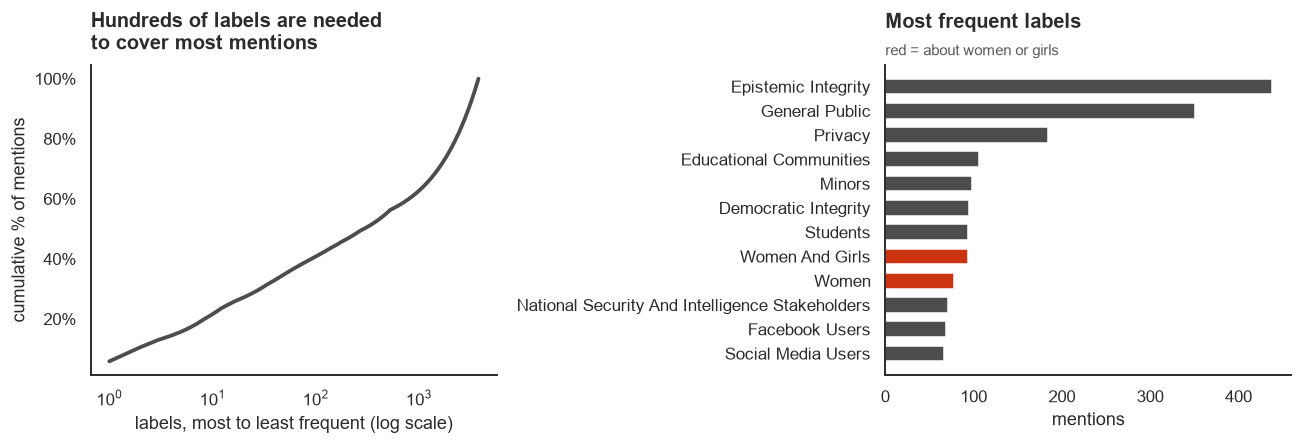

In [56]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

ax[0].plot(np.arange(1, len(cov) + 1), cov.values * 100, color=CMP_A, lw=2.5)
ax[0].set_xscale("log")
ax[0].yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax[0].set_xlabel("labels, most to least frequent (log scale)")
ax[0].set_ylabel("cumulative % of mentions")
titles(ax[0], "Hundreds of labels are needed\nto cover most mentions")

top = vc.head(12)[::-1]
ax[1].barh(top.index, top.values, color=[HIGHLIGHT if t in women.index else CMP_A for t in top.index], height=0.65)
ax[1].set_xlabel("mentions")
titles(ax[1], "Most frequent labels", "red = about women or girls")

fig.tight_layout()
save(fig, "00b_harmed_fragmentation")
plt.show()

With labels this short and this rare, a topic model alone does not give clean groups. We first group the labels with **keyword rules**, which are easy to read and check. A label can match several groups. *General public* is only used when nothing more specific fits, and harms to values ("Epistemic Integrity", "Privacy") get their own group because they are not people.

In [ ]:
GROUP_RULES = {
    "Women and girls": r"\bwom[ae]n\b|\bgirls?\b|\bfemale",
    "Children, parents, students, teachers": r"minor|child|\bkids?\b|teen|adolescen|student|school|youth|underage|pupil|educat|teacher|parent|famil",
    "Social media / platform users": r"social media|facebook|instagram|twitter|tiktok|youtube|\bx \(|whatsapp|reddit|snapchat|linkedin|telegram|meta users|google users|\bx users|\busers?\b|e?mail",
    "Chatbot / AI users": r"chatgpt|chatbot|openai|replika|character\.?ai|\bllm|\bai users|users of ai|ai agent|gemini|copilot|grok|claude|\bgpt",
    "Consumers and customers": r"consumer|customer|shopper|buyer|subscriber|tenant|borrower|applicant|tourist",
    "Patients and health": r"patient|health|mental|suicid|medical|vulnerable",
    "Workers and job seekers": r"worker|employee|job|driver|labou?r|candidate|staff|truck",
    "Professionals": r"researcher|scientist|developer|engineer|lawyer|attorney|professional|responder|firefighter|doctor|physician|nurse",
    "Creators and artists": r"artist|creator|author|writer|actor|musician|illustrator|copyright|performer|voice",
    "Racial, ethnic, LGBTQ+, disabled": r"black|african|asian|latin|hispanic|minorit|racial|ethnic|muslim|jewish|lgbt|gay|\btrans\b|indigenous|immigrant|disabilit|disabled|marginali|cisgender|queer|refugee|roma|romani|traveller|neurodivergent",
    "Public figures and journalists": r"public figure|celebrit|politic|president|trump|biden|journalis|\bmedia\b|news",
    "Voters and elections": r"voter|electorate|election|democra",
    "Victims of deepfakes, fraud, scams": r"deepfake|fraud|scam|victim|impersonat",
    "Data subjects (biometric, personal)": r"data subject|biometric|personal data",
    "Road users": r"\broad\b|pedestrian|passenger|cyclist|motorist|traffic",
    "Investors and finance": r"investor|bank|financial|elderly|retire",
    "Organisations and states": r"microsoft|musk|publisher|law enforcement|compan|business|organi[sz]ation|government|institution|police|court|universit|agency|department|emergency services|military|national security|stakeholder|nation|^(bbc|google|tesla|anthropic|disney|waymo|arup|usaid|openai)$",
}
GENERAL_PUBLIC = r"general public|\bpublic\b|citizen|society|\bpeople\b|everyone|resident|participants|communit|fans"
VALUES = r"integrity|privacy|trust|safety|security|rights|autonomy|dignity|equality|environment|freedom|reputation"

def label_groups(label):
    groups = [g for g, pattern in GROUP_RULES.items() if re.search(pattern, label, re.I)]
    if not groups and re.search(GENERAL_PUBLIC, label, re.I):
        groups = ["General public"]
    if not groups and re.search(VALUES, label, re.I):
        groups = ["Abstract values (not people)"]
    return groups

In [59]:
lab = pd.DataFrame({"label": vc.index, "mentions": vc.values})
lab["groups"] = lab["label"].map(label_groups)
lab["matched"] = lab["groups"].map(len) > 0

print(f"Keyword rules: {lab.matched.mean():.0%} of labels, "
      f"{lab.loc[lab.matched, 'mentions'].sum() / lab.mentions.sum():.0%} of mentions grouped")
print("Most frequent labels still without a group:")
lab.loc[~lab.matched, ["label", "mentions"]].head(15).set_index("label")

Keyword rules: 53% of labels, 73% of mentions grouped
Most frequent labels still without a group:


,mentions
label,
Kamala Harris,8
Ukraine,7
Cnn,6
Bbc,6
Barack Obama,5
Google,5
Taylor Swift,5
Targets Of Autonomous Ai Enabled Intrusion Operations,5
Albin Kurti,5


Most of what is left are **names of people, organisations and countries** ("Taylor Swift", "Universal Music Group", "Ukraine"), which no keyword list can cover. For these we use spaCy's named-entity model (`en_core_web_sm`): a label recognised as a person goes to *Named individuals*, an organisation or a label that is only a place name goes to *Organisations and states* (states = countries). A few well-known companies are missed by spaCy because the export writes them in title case ("Bbc"), so they are added by name to the keyword rule.

In [60]:
import spacy

nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])

label_to_groups = dict(zip(lab["label"], lab["groups"]))
unmatched = lab.loc[~lab.matched, "label"].tolist()
for label, doc in zip(unmatched, nlp.pipe(unmatched, batch_size=200)):
    kinds = {e.label_ for e in doc.ents}
    if "PERSON" in kinds:
        label_to_groups[label] = ["Named individuals"]
    elif "ORG" in kinds or (len(doc.ents) == 1 and doc.ents[0].text == label and doc.ents[0].label_ in ["GPE", "LOC"]):
        label_to_groups[label] = ["Organisations and states"]

lab["groups"] = lab["label"].map(label_to_groups)
lab["matched"] = lab["groups"].map(len) > 0
print(f"After spaCy: {lab.matched.mean():.0%} of labels, "
      f"{lab.loc[lab.matched, 'mentions'].sum() / lab.mentions.sum():.0%} of mentions grouped")

After spaCy: 86% of labels, 91% of mentions grouped


In [62]:
named = lab[lab["groups"].map(lambda g: g == ["Named individuals"])]
print(f"{len(named):,} labels tagged as named individuals. Random sample of 40 to check by hand:")
print(" | ".join(named["label"].sample(40, random_state=1)))

897 labels tagged as named individuals. Random sample of 40 to check by hand:
Gilberto Alcazar Lopez | Collien Fernandes | John Piscitella | Lee Ji Hye | Dennis Morida | Scarlett Johansson | Kelly Clarkson | Mary Franson | Kimberlee Williams | Ian Borg | Mcsweeny Synkar And Kachouroff Pllc | Shannon Carpenter | Claire Vo | Kate Garraway | Noa Kirel | Monica Geingos | Nijeer Parks | Steve Cohen | Albin Kurti | Mark A. Young | Paul Kagame | Bee Cups | Xiomara Castro | Rona Wang | Erik Rossiter | Mike Schmitz | Butler Snow | Monterrey Water And Drainage Services | Dumitru Alaiba | Gema | Ted Hui | Taylor Swift | Patrizio Bertelli | Bita Hemmati | Eric Horvitz | Marian Tofan | Jeff Koinange | Ivan Hristanov | Ciro Pellegrino | Jack Tame


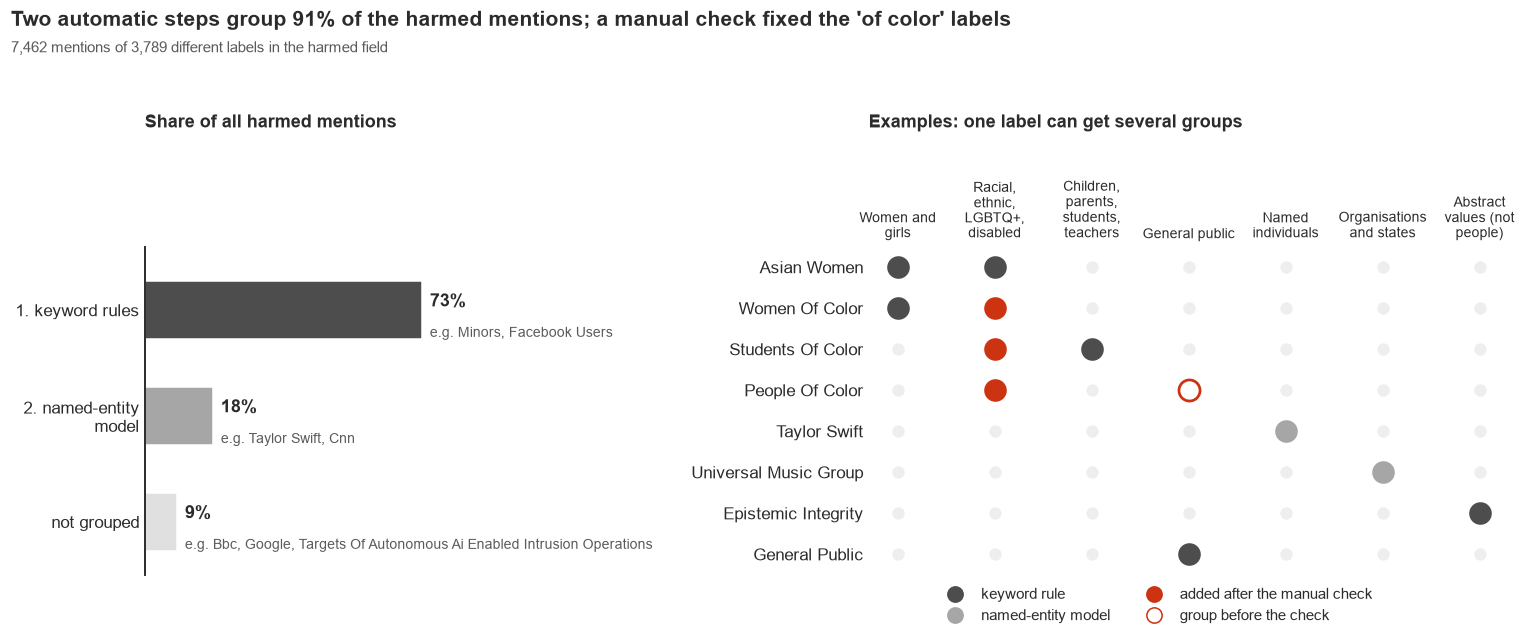

In [66]:
step = lab["label"].map(lambda l: "keyword rules" if label_groups(l) else
                        ("named-entity model" if label_to_groups[l] else "not grouped"))
by_step = (lab.groupby(step)["mentions"].sum() / lab["mentions"].sum() * 100).reindex(
    ["keyword rules", "named-entity model", "not grouped"])
step_examples = {"keyword rules": "Minors, Facebook Users",
                 "named-entity model": "Taylor Swift, Cnn",
                 "not grouped": ", ".join(lab.loc[~lab.matched, "label"].head(3))}

EXAMPLES = ["Asian Women", "Women Of Color", "Students Of Color", "People Of Color",
            "Taylor Swift", "Universal Music Group", "Epistemic Integrity", "General Public"]
BEFORE_FIX = {"People Of Color": "General public"}   # its group before the "of color" rule was added
cols = ["Women and girls", "Racial, ethnic, LGBTQ+, disabled", "Children, parents, students, teachers",
        "General public", "Named individuals", "Organisations and states", "Abstract values (not people)"]
STEP_COLOR = {"keyword rules": CMP_A, "named-entity model": CMP_B, "not grouped": "#E0E0E0"}

fig, ax = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw={"width_ratios": [1, 1.3]})

y = np.arange(len(by_step))
ax[0].barh(y, by_step.values, color=[STEP_COLOR[s] for s in by_step.index], height=0.55)
for yi, (s, v) in zip(y, by_step.items()):
    ax[0].text(v + 2, yi - 0.08, f"{v:.0f}%", va="center", fontsize=12, fontweight="bold")
    ax[0].text(v + 2, yi + 0.22, f"e.g. {step_examples[s]}", va="center", fontsize=9, color="#5A5A5A")
ax[0].set_yticks(y, ["1. keyword rules", "2. named-entity\n    model", "not grouped"])
ax[0].set_ylim(len(y) - 0.5, -0.6)
ax[0].set_xlim(0, 130)
ax[0].set_xticks([])
ax[0].tick_params(length=0)
ax[0].spines["bottom"].set_visible(False)
ax[0].set_title("Share of all harmed mentions", fontsize=11.5, pad=78)

for yi, label in enumerate(EXAMPLES):
    s = "keyword rules" if label_groups(label) else "named-entity model"
    for x, g in enumerate(cols):
        ax[1].scatter(x, yi, s=50, color="#EEEEEE", zorder=1)
        if g in label_to_groups[label]:
            fixed = "of color" in label.lower() and g.startswith("Racial")
            ax[1].scatter(x, yi, s=190, color=HIGHLIGHT if fixed else STEP_COLOR[s], zorder=2)
        if BEFORE_FIX.get(label) == g:
            ax[1].scatter(x, yi, s=190, facecolor="white", edgecolor=HIGHLIGHT, linewidth=1.8, zorder=2)
ax[1].set_xticks(range(len(cols)), [textwrap.fill(c, 14) for c in cols], fontsize=9)
ax[1].xaxis.tick_top()
ax[1].set_yticks(range(len(EXAMPLES)), EXAMPLES)
ax[1].set_ylim(len(EXAMPLES) - 0.5, -0.5)
ax[1].tick_params(length=0)
ax[1].spines[["left", "bottom"]].set_visible(False)
ax[1].set_title("Examples: one label can get several groups", fontsize=11.5, pad=78)

handles = [plt.Line2D([], [], marker="o", ls="", markersize=10, color=CMP_A, label="keyword rule"),
           plt.Line2D([], [], marker="o", ls="", markersize=10, color=CMP_B, label="named-entity model"),
           plt.Line2D([], [], marker="o", ls="", markersize=10, color=HIGHLIGHT, label="added after the manual check"),
           plt.Line2D([], [], marker="o", ls="", markersize=10, mfc="white", mec=HIGHLIGHT, label="group before the check")]
ax[1].legend(handles=handles, loc="upper center", bbox_to_anchor=(0.45, 0), ncol=2, fontsize=9.5)

fig.suptitle("Two automatic steps group 91% of the harmed mentions; a manual check fixed the 'of color' labels",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.0)
fig.text(0.01, 0.935, f"{lab['mentions'].sum():,} mentions of {len(lab):,} different labels in the harmed field",
         fontsize=9.5, color="#5A5A5A")
fig.tight_layout(rect=(0, 0, 1, 0.93))
save(fig, "00g_harmed_grouping_steps")
plt.show()

In this sample 5 of 40 (~12%) are wrong, mostly organisations read as people (law firms, a water company). Public figures and private persons end up in the same group, since spaCy cannot tell them apart. That is good enough for counting, but *Named individuals* should be read as a rough group.

In [63]:
def incident_groups(labels):
    groups = sorted({g for t in labels for g in label_to_groups.get(t, [])})
    return groups if groups else ["Not grouped"]

inc_raw["harmed_groups"] = inc_raw["harmed_list"].map(incident_groups)
grouped = inc_raw["harmed_groups"].map(lambda g: g != ["Not grouped"])

pd.DataFrame({"grouped %": [lab.matched.mean() * 100,
                            lab.loc[lab.matched, "mentions"].sum() / lab.mentions.sum() * 100,
                            grouped.mean() * 100]},
             index=["labels", "mentions", "incidents"]).round(0)

,grouped %
labels,86.0
mentions,91.0
incidents,97.0


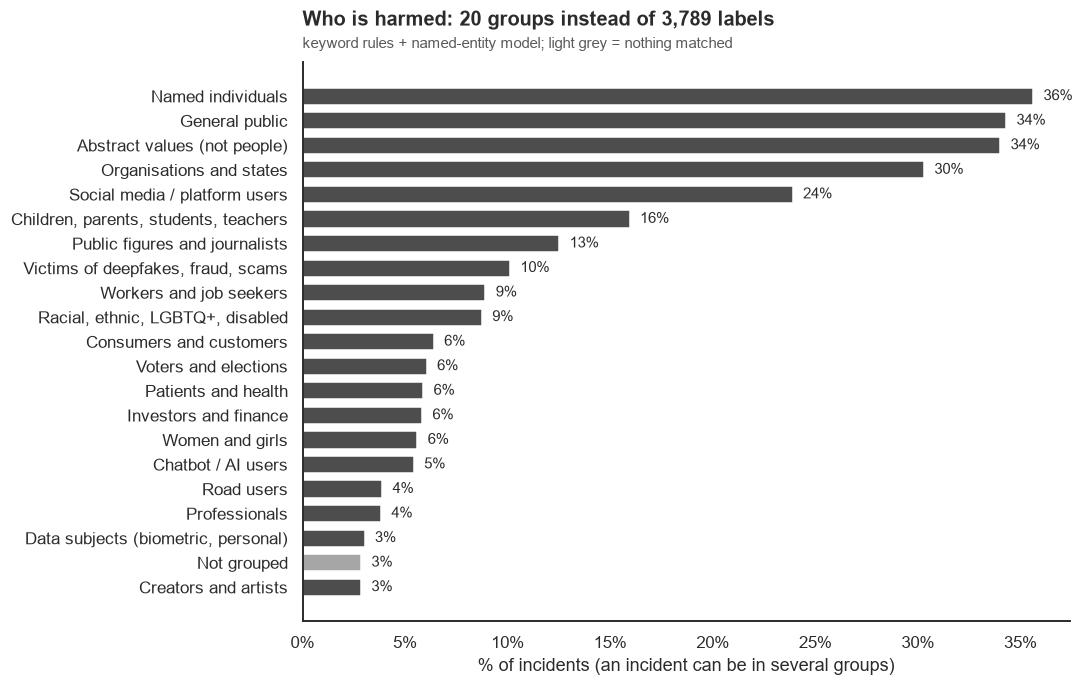

In [64]:
share = (inc_raw["harmed_groups"].explode().value_counts() / len(inc_raw) * 100).sort_values()

fig, ax = plt.subplots(figsize=(9, 6.6))
ax.barh(share.index, share.values, color=[CMP_B if g == "Not grouped" else CMP_A for g in share.index], height=0.7)
for y, v in enumerate(share.values):
    ax.text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=10)
ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.set_xlabel("% of incidents (an incident can be in several groups)")
titles(ax, f"Who is harmed: {share.size - 1} groups instead of {len(lab):,} labels",
       "keyword rules + named-entity model; light grey = nothing matched")
save(fig, "00d_harmed_groups")
plt.show()

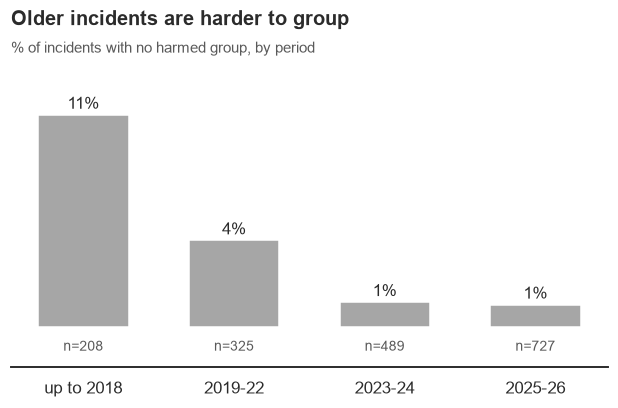

In [65]:
not_grouped = (~grouped).groupby(period, observed=True).agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(not_grouped.index.astype(str), not_grouped["mean"] * 100, color=CMP_B, width=0.6)
for x, (p, n) in enumerate(zip(not_grouped["mean"] * 100, not_grouped["size"])):
    ax.text(x, p + 0.3, f"{p:.0f}%", ha="center", fontsize=11)
    ax.text(x, -1.2, f"n={n}", ha="center", fontsize=9, color="#5A5A5A")
ax.set_ylim(-2, not_grouped["mean"].max() * 100 * 1.25)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
titles(ax, "Older incidents are harder to group",
       "% of incidents with no harmed group, by period")
save(fig, "00e_not_grouped_by_period")
plt.show()

The grouping works better on recent incidents, probably because newer labels follow more standard wording. Comparisons of harmed groups across periods are therefore slightly biased towards the recent years.

#### Topic model of the harmed field

As a check of the keyword groups we also fit a topic model (NMF on TF-IDF) to the harmed text of each incident. Person names are too rare to be picked up as words, so labels tagged as *Named individuals* are first replaced by the token `namedperson`.

There is no single correct number of topics *k*, so we compare several values on three measures: **coherence** (do the top words of a topic appear together?), **stability** (do different random starts give the same topics?) and **agreement with the keyword groups**.

In [67]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import normalized_mutual_info_score

def harmed_text(labels):
    words = ["namedperson" if label_to_groups.get(t) == ["Named individuals"] else t for t in labels]
    return " ; ".join(t for t in words if t != "Unknown")

h_text = inc_raw["harmed_list"].map(harmed_text)
h_text = h_text[h_text != ""]

vec = TfidfVectorizer(stop_words="english", min_df=3, max_df=0.5, sublinear_tf=True)
Xh = vec.fit_transform(h_text)
B = CountVectorizer(vocabulary=vec.vocabulary_, binary=True).fit_transform(h_text)
print(f"{Xh.shape[0]:,} incidents, {Xh.shape[1]} words")

1,744 incidents, 629 words


In [68]:
def umass(top_words, B):
    co = (B.T @ B).toarray()
    scores = [np.log((co[w[m], w[l]] + 1) / co[w[l], w[l]])
              for w in top_words for m in range(1, len(w)) for l in range(m)]
    return np.mean(scores)

group_rank = {g: i for i, g in enumerate(share.sort_values(ascending=False).index)}
rule_label = inc_raw.loc[h_text.index, "harmed_groups"].map(lambda g: min(g, key=group_rank.get))

rows = []
for k in [4, 6, 8, 10, 12, 15, 20, 25]:
    fits = [NMF(k, init="random", random_state=s, max_iter=400).fit(Xh) for s in range(4)]
    assign = [f.transform(Xh).argmax(axis=1) for f in fits]
    top_words = np.argsort(-fits[0].components_, axis=1)[:, :8]
    rows.append({"k": k,
                 "coherence": umass(top_words, B),
                 "stability": np.mean([normalized_mutual_info_score(assign[i], assign[j])
                                       for i in range(4) for j in range(i + 1, 4)]),
                 "agreement with keyword groups": normalized_mutual_info_score(rule_label, assign[0])})
sel = pd.DataFrame(rows).set_index("k")
sel.round(3)

,coherence,stability,agreement with keyword groups
k,,,
4,-2.108,0.870,0.289
6,-2.221,0.772,0.262
8,-2.307,0.799,0.261
10,-2.305,0.736,0.275
12,-2.377,0.742,0.272
15,-2.334,0.708,0.281
20,-2.319,0.675,0.275
25,-2.284,0.702,0.274


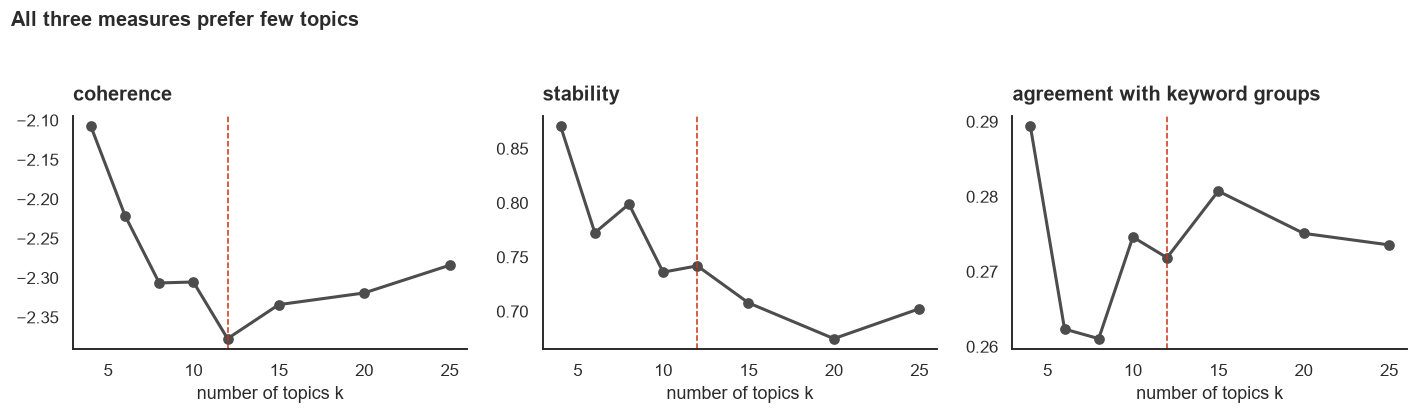

In [70]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, col in zip(ax, sel.columns):
    a.plot(sel.index, sel[col], marker="o", color=CMP_A, lw=2)
    a.axvline(12, color=HIGHLIGHT, lw=1, ls="--")
    a.set_xlabel("number of topics k")
    titles(a, col)
fig.suptitle("All three measures prefer few topics", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout()
save(fig, "00c_choose_k")
plt.show()

All three measures are best at k = 4, which is expected (fewer topics are always more stable), but 4 topics are far too coarse for 20 harmed groups. From k = 8 upwards the curves are almost flat, so they don't pick a winner. We use **k = 12** because there most topics clearly match one keyword group. This is a judgment call, not an optimum.

In [77]:
K = 12
nmf_h = NMF(K, init="nndsvd", random_state=SEED, max_iter=500).fit(Xh)
topic = pd.Series(nmf_h.transform(Xh).argmax(axis=1), index=h_text.index)
inc_raw["harmed_topic"] = topic
voc = vec.get_feature_names_out()

pairs = pd.DataFrame({"topic": topic, "group": inc_raw.loc[h_text.index, "harmed_groups"]}).explode("group")
size = topic.value_counts()
main_group = pairs.groupby("topic")["group"].agg(lambda s: s.value_counts().index[0])
main_share = pairs.groupby("topic")["group"].agg(lambda s: s.value_counts().iloc[0]) / size * 100

topics = pd.DataFrame({"top words": [", ".join(voc[np.argsort(-nmf_h.components_[k])[:6]]) for k in range(K)],
                       "incidents": size,
                       "main keyword group": main_group,
                       "% in main group": main_share.round(0)}).sort_values("incidents", ascending=False)
topics

,top words,incidents,main keyword group,% in main group
2,"users, facebook, social, media, instagram, twi...",284,Social media / platform users,95.0
1,"general, public, investors, india, australia, ...",277,General public,95.0
0,"namedperson, family, investors, fans, employee...",214,Named individuals,86.0
3,"integrity, epistemic, democratic, voters, judi...",155,Abstract values (not people),75.0
5,"students, educational, communities, school, mi...",138,"Children, parents, students, teachers",83.0
4,"women, girls, victims, abuse, deepfake, non",126,"Victims of deepfakes, fraud, scams",73.0
11,"privacy, data, biometric, subjects, ai, patients",122,Abstract values (not people),69.0
6,"people, black, seeking, medical, advice, jewish",116,General public,58.0
10,"security, national, stakeholders, intelligence...",112,Organisations and states,89.0
8,"drivers, tesla, road, uber, amazon, motorists",92,Workers and job seekers,63.0


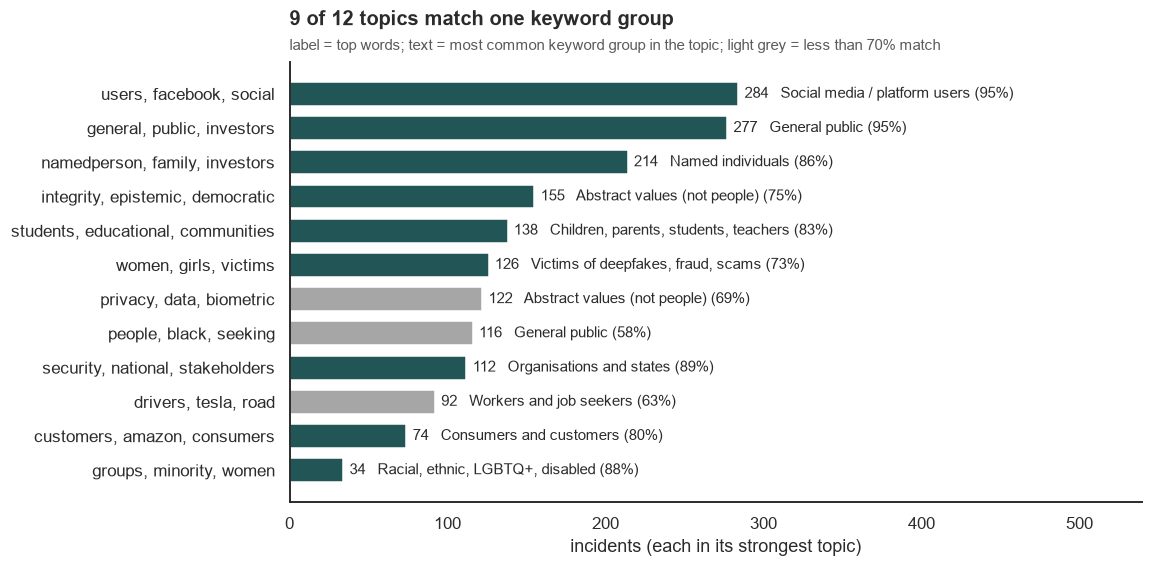

In [93]:
t = topics.iloc[::-1]
labels = [", ".join(w.split(", ")[:3]) for w in t["top words"]]

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(labels, t["incidents"], color=[CMP_A if p >= 70 else CMP_B for p in t["% in main group"]], height=0.7)
for y, (n, g, p) in enumerate(zip(t["incidents"], t["main keyword group"], t["% in main group"])):
    ax.text(n + 4, y, f"{n}   {g} ({p:.0f}%)", va="center", fontsize=9.5)
ax.set_xlim(0, t["incidents"].max() * 1.9)
ax.set_xlabel("incidents (each in its strongest topic)")
titles(ax, f"{(t['% in main group'] >= 70).sum()} of {K} topics match one keyword group",
       "label = top words; text = most common keyword group in the topic; light grey = less than 70% match")
save(fig, "00f_harmed_topics")
plt.show()

The topic model and the keyword groups mostly agree, which supports the keyword grouping. With the `namedperson` token the model now finds a topic for named individuals as well (about 210 incidents). It also shows that harm to **women and girls** sits together with deepfake abuse in one topic. The weaker topics (*people, black, medical ...*) mix several small groups.

### 2.7 Editor notes

30% of incidents have an editor note. Before using all incidents we check whether the notes flag problems, e.g. an incident that is a duplicate or should not be in the database.

In [79]:
notes = inc_raw["Editor Notes"].dropna()
checks = {"timeline / dates": r"timeline|date",
          "refers to another incident": r"see also|incident \d+",
          "duplicate": r"duplicat",
          "should be an issue, not an incident": r"reclassification as an issue|migrated to issue"}
display(pd.Series({k: notes.str.contains(p, case=False).sum() for k, p in checks.items()}).to_frame("notes"))

flagged = inc_raw["Editor Notes"].str.contains(checks["should be an issue, not an incident"], case=False, na=False) \
          | inc_raw["title"].str.contains("migrated to issue", case=False)
inc_raw.loc[flagged, ["Incident ID", "year", "title", "Editor Notes"]]

,notes
timeline / dates,359
refers to another incident,151
duplicate,1
"should be an issue, not an incident",2


,Incident ID,year,title,Editor Notes
20,21,2016,Tougher Turing Test Exposes Chatbots’ Stupidit...,NaN
246,252,2022,Remotely Operated Taser-Armed Drones Proposed ...,This incident ID should be reviewed for possib...
455,466,2023,AI-Generated Text Detectors Reportedly Misclas...,This record should be reviewed for possible re...


The notes are mostly timelines and links to related incidents. The one "duplicate" is about a duplicate licence plate, not a duplicate incident. Three incidents are flagged as possibly not real incidents: one was already moved to an "issue" by the editors (its title says *migrated to Issue*), two are only marked for review. We drop the migrated one and keep the other two, since the editors have not decided yet. This is 3 out of 1,749 incidents, so it does not change any result.

In [80]:
inc_raw = inc_raw[~inc_raw["title"].str.contains("migrated to issue", case=False)].copy()
print(f"{len(inc_raw):,} incidents left")

1,748 incidents left


### 2.8 Incident text

For the topic models and the classifier, each incident is described by its title and description. A quick check of length, empty texts and duplicates:

In [81]:
text = inc_raw["title"].fillna("") + ". " + inc_raw["description"].fillna("")
words = text.str.split().str.len()

print("Empty texts:", (inc_raw["description"].fillna("").str.strip() == "").sum())
print("Duplicate titles:", inc_raw["title"].duplicated().sum(), "| duplicate descriptions:", inc_raw["description"].duplicated().sum())
print(f"Words per incident: median {words.median():.0f}, min {words.min()}, max {words.max()}")
inc_raw.loc[words < 20, ["Incident ID", "year", "description"]]

Empty texts: 0
Duplicate titles: 0 | duplicate descriptions: 0
Words per incident: median 68, min 10, max 119


,Incident ID,year,description
13,14,2017,Google Cloud's Natural Language API provided r...
15,16,2015,Google Photos image processing software mistak...
18,19,2013,Advertisements chosen by Google Adsense are re...
25,26,2017,Vietnamese security firm Bkav created an impro...
38,39,2017,University of Washington researchers made a de...
44,45,2011,Google's autocomplete feature alongside its im...
59,60,2017,FaceApp is criticized for offering racist filt...
86,87,2020,UK passport photo checker shows bias against d...
122,125,2020,Amazon’s robotic fulfillment centers have high...


Every incident has a text, there are no duplicates, and the texts are short and similar in length (median 68 words), because the editors write them in a fixed style. The few very short ones are old incidents; they are kept.

### 2.9 Reports

The Reports sheet should contain news articles. About 10% of the rows have no title, URL, source or authors, so first we look at what these rows are.

In [82]:
empty = rep_raw["Title"].isna()
print("Rows without a title:", empty.sum())
display(rep_raw.loc[empty, "Tags"].value_counts().to_frame("tag of the empty rows"))
display(rep_raw.loc[empty, "Date Published"].dt.year.value_counts().to_frame("published (year)"))
rep_raw.loc[empty].head(3)

Rows without a title: 812


,tag of the empty rows
Tags,
Variant:Unreviewed,811
Variant:Approved,1


,published (year)
Date Published,
1967,608
1970,143
2026,34
2025,9
2024,5
2000,3
2023,2
2019,2
2014,1


,Report Number,Title,URL,Source Domain,Date Published,Date Downloaded,Authors,Submitters,Language,Tags,Description,Is Incident Report
2399,2587,NaN,NaN,NaN,2000-01-01,2023-02-08,NaN,"Pablo Costa, New Submitter",en,Variant:Approved,NaN,False
3016,3205,NaN,NaN,NaN,2023-08-03,2023-08-03,NaN,Rajasekar,en,Variant:Unreviewed,NaN,False
3257,3447,NaN,NaN,NaN,2019-03-10,2023-12-07,NaN,Enrique Chaparro,en,Variant:Unreviewed,NaN,False


In [83]:
rep_raw[rep_raw["Date Published"].dt.year < 1900]

,Report Number,Title,URL,Source Domain,Date Published,Date Downloaded,Authors,Submitters,Language,Tags,Description,Is Incident Report
6069,6259,NaN,NaN,NaN,1025-09-29,2025-10-16,NaN,Anonymous,en,Variant:Unreviewed,NaN,False


All the empty rows are tagged *Variant*: these are not news articles but submissions of incident variants. They also carry placeholder dates (1967, 1970 and even year 1025), which would distort any timeline. We drop them.

(The year 1025 is one row whose date is stored in Excel as a negative day number, -319314; it was downloaded in October 2025, so it is most likely a typo or it could have been a date before 1900 which Excel doesn't read.)

In [84]:
rep = rep_raw[~rep_raw["Tags"].fillna("").str.startswith("Variant")].copy()
print(f"{len(rep):,} reports left; published from {rep['Date Published'].min().date()} to {rep['Date Published'].max().date()}")

7,142 reports left; published from 1996-04-03 to 2026-10-15


In [86]:
dup = rep[rep["URL"].duplicated(keep=False)].sort_values("URL")
print("Reports whose URL appears more than once:", len(dup), "| extra copies:", rep["URL"].duplicated().sum())
dup[["Report Number", "Title", "Source Domain", "Date Published"]].head(6)

Reports whose URL appears more than once: 121 | extra copies: 62


,Report Number,Title,Source Domain,Date Published
4128,4318,SF couple describes feeling 'trapped' riding i...,abc7news.com,2024-02-08
4127,4317,SF couple describes feeling 'trapped' riding i...,abc7news.com,2024-02-08
5091,5281,The Deepfake is a powerful weapon in the war i...,africanarguments.org,2024-10-23
5092,5282,The Deepfake is a powerful weapon in the war i...,africanarguments.org,2024-10-23
5093,5283,The Deepfake is a powerful weapon in the war i...,africanarguments.org,2024-10-23
7126,7319,Two men charged with creating AI-generated por...,apnews.com,2026-05-21


Some articles appear two or three times with consecutive report numbers, i.e. the same article was attached to several incidents. Since we look at the reports as a picture of media coverage (they cannot be linked back to incidents in this export), each article should count once.

In [87]:
rep = rep.drop_duplicates(subset="URL").copy()
print(f"{len(rep):,} unique articles")

7,080 unique articles


In [88]:
lang = rep["Language"].value_counts(normalize=True) * 100
submit = rep["Submitters"].value_counts(normalize=True) * 100
src = rep["Source Domain"].value_counts(normalize=True) * 100

print(f"English: {lang['en']:.0f}% | next: " + ", ".join(f"{k} {v:.1f}%" for k, v in lang.iloc[1:5].items()))
print(f"Top submitter: {submit.index[0]} ({submit.iloc[0]:.0f}% of reports); top 3 together {submit.head(3).sum():.0f}%")
print(f"{len(src):,} sources; top 10 have {src.head(10).sum():.0f}% of reports")
print("Not linked to an incident ('issue' reports):", (~rep["Is Incident Report"]).sum())

English: 95% | next: es 1.1%, it 0.4%, de 0.4%, fr 0.4%
Top submitter: Daniel Atherton (55% of reports); top 3 together 76%
2,177 sources; top 10 have 19% of reports
Not linked to an incident ('issue' reports): 450


Three things to keep in mind for the media section:
* 95% of the reports are in English. The text models use English reports only; the other languages are too small to model separately.
* One person submitted more than half of all reports, so what gets into the database partly reflects the interests of a few contributors.
* About 6% are *issue* reports (about AI risks in general, not one incident). They are kept and shown separately where it matters.

In [89]:
rep["year"] = rep["Date Published"].dt.year
rep["text"] = (rep["Title"].fillna("") + ". " + rep["Description"].fillna("")).str.strip(". ")
rep["english"] = rep["Language"] == "en"

### 2.10 Final incident table

All decisions from this section in one place: shorter column names, the seven risk domains, intent without *Other*, the four periods and one text column for the models.

In [90]:
inc = inc_raw.rename(columns={"Incident ID": "id", "Risk Domain": "domain_raw", "Risk Subdomain": "subdomain",
                              "Responsible Entity": "responsible", "Implicated Systems": "systems",
                              "Lives Lost": "lives_lost", "Sector of Deployment": "sector"}).copy()

inc["domain"] = pd.Categorical(inc["domain_raw"].map(DOMAIN_MAP), categories=DOMAINS)
inc["classified"] = inc["domain"].notna()
inc["dom_label"] = inc["domain"].astype(object).fillna("Unclassified")
inc["intent_s"] = inc["Intent"].where(inc["Intent"].isin(INTENTS))
inc["period"] = pd.cut(inc["year"], [0, 2018, 2022, 2024, 2026], labels=PERIODS)
inc["text"] = inc["title"] + ". " + inc["description"]
inc["ents"] = ["|".join(sorted(set(d + v + h + tokens(s)))).lower()
               for d, v, h, s in zip(inc["deployer_list"], inc["developer_list"], inc["harmed_list"], inc["systems"])]

print(f"{len(inc):,} incidents, {inc['classified'].sum():,} with a risk domain ({inc['classified'].mean():.0%})")
inc["dom_label"].value_counts().to_frame("incidents").T

1,748 incidents, 1,495 with a risk domain (86%)


dom_label,Malicious use,System failures,Unclassified,Discrimination & toxicity,Misinformation,Privacy & security,Human-computer interaction,Socioeconomic & environmental
incidents,566,312,253,243,196,112,42,24


## 3. What can we trust? Coverage of the classifications

Besides the basic fields, the AIID has three classification layers. The MIT risk taxonomy covers most incidents, CSET and GMF only a small part, so the analysis is built on MIT. The newest incidents are often not classified yet.

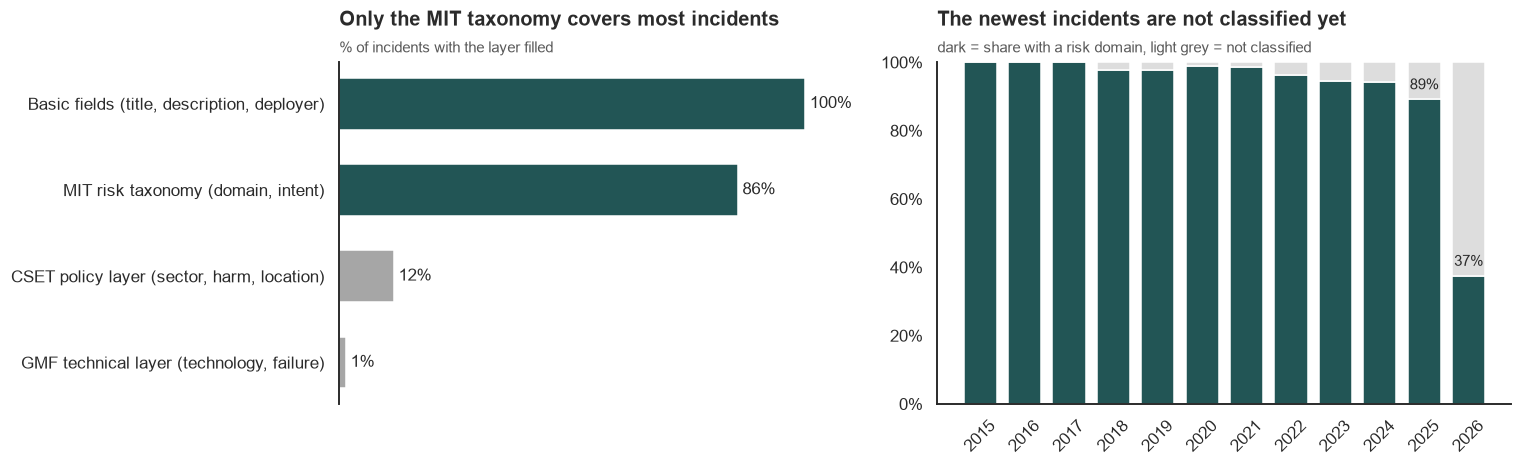

In [94]:
layers = pd.Series({"Basic fields (title, description, deployer)": inc["description"].notna().mean(),
                    "MIT risk taxonomy (domain, intent)": inc["classified"].mean(),
                    "CSET policy layer (sector, harm, location)": inc["sector"].notna().mean(),
                    "GMF technical layer (technology, failure)": inc["AI Technology"].notna().mean()}) * 100
by_year = inc[inc["year"] >= 2015].groupby("year")["classified"].mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1.1]})

ax[0].barh(layers.index[::-1], layers.values[::-1], color=[CMP_A if v > 50 else CMP_B for v in layers.values[::-1]], height=0.6)
for y, v in enumerate(layers.values[::-1]):
    ax[0].text(v + 1, y, f"{v:.0f}%", va="center", fontsize=11)
ax[0].set_xlim(0, 112)
ax[0].set_xticks([])
ax[0].spines["bottom"].set_visible(False)
titles(ax[0], "Only the MIT taxonomy covers most incidents", "% of incidents with the layer filled")

ax[1].bar(by_year.index, by_year.values, color=CMP_A, width=0.75)
ax[1].bar(by_year.index, 100 - by_year.values, bottom=by_year.values, color=DOM_COLOR["Unclassified"], width=0.75)
for x in [2025, 2026]:
    ax[1].text(x, by_year[x] + 2, f"{by_year[x]:.0f}%", ha="center", va="bottom", fontsize=10)
ax[1].set_xticks(by_year.index)
ax[1].tick_params(axis="x", labelrotation=45)
ax[1].set_ylim(0, 100)
ax[1].yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
titles(ax[1], "The newest incidents are not classified yet", "dark = share with a risk domain, light grey = not classified")

fig.tight_layout()
save(fig, "01_coverage")
plt.show()

## 4. The big picture: how many incidents, and of what kind?

### 4.1 Incidents per year

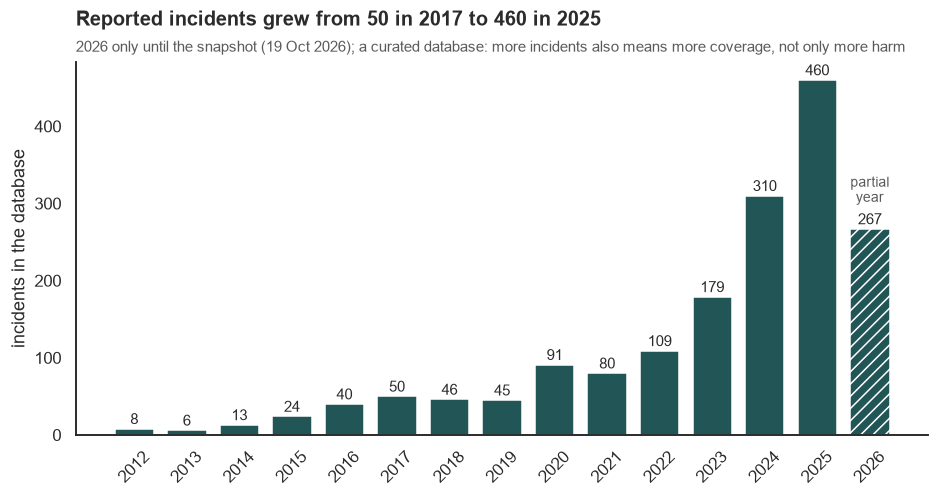

In [95]:
per_year = inc[inc["year"] >= 2012].groupby("year").size()

fig, ax = plt.subplots(figsize=(10, 4.4))
bars = ax.bar(per_year.index, per_year.values, color=CMP_A, width=0.75)
bars[-1].set_hatch("///")
bars[-1].set_edgecolor("white")
for x, v in per_year.items():
    ax.text(x, v + 6, f"{v}", ha="center", fontsize=9.5)
ax.text(2026, per_year[2026] + 35, "partial\nyear", ha="center", fontsize=9, color="#5A5A5A")
ax.set_xticks(per_year.index)
ax.tick_params(axis="x", labelrotation=45)
ax.set_ylabel("incidents in the database")
titles(ax, f"Reported incidents grew from {per_year[2017]} in 2017 to {per_year[2025]} in 2025",
       f"2026 only until the snapshot ({SNAPSHOT}); a curated database: more incidents also means more coverage, not only more harm")
save(fig, "02_incidents_per_year")
plt.show()

### 4.2 Types of harm over time

In [96]:
counts = pd.crosstab(inc["year"], inc["dom_label"]).reindex(columns=DOMAINS + ["Unclassified"], fill_value=0).loc[2015:]
shares = pd.crosstab(inc["period"], inc["domain"], normalize="index").reindex(columns=DOMAINS) * 100
n_period = inc[inc["classified"]].groupby("period", observed=True).size()
shares

domain,Malicious use,System failures,Discrimination & toxicity,Misinformation,Privacy & security,Human-computer interaction,Socioeconomic & environmental
period,,,,,,,
up to 2018,5.825243,43.203883,33.009709,1.941748,10.679612,0.970874,4.368932
2019-22,15.094340,35.849057,28.616352,6.918239,8.176101,3.773585,1.572327
2023-24,47.722343,12.798265,11.713666,18.655098,6.290672,1.952278,0.867679
2025-26,56.078431,9.803922,5.882353,16.470588,6.862745,3.725490,1.176471


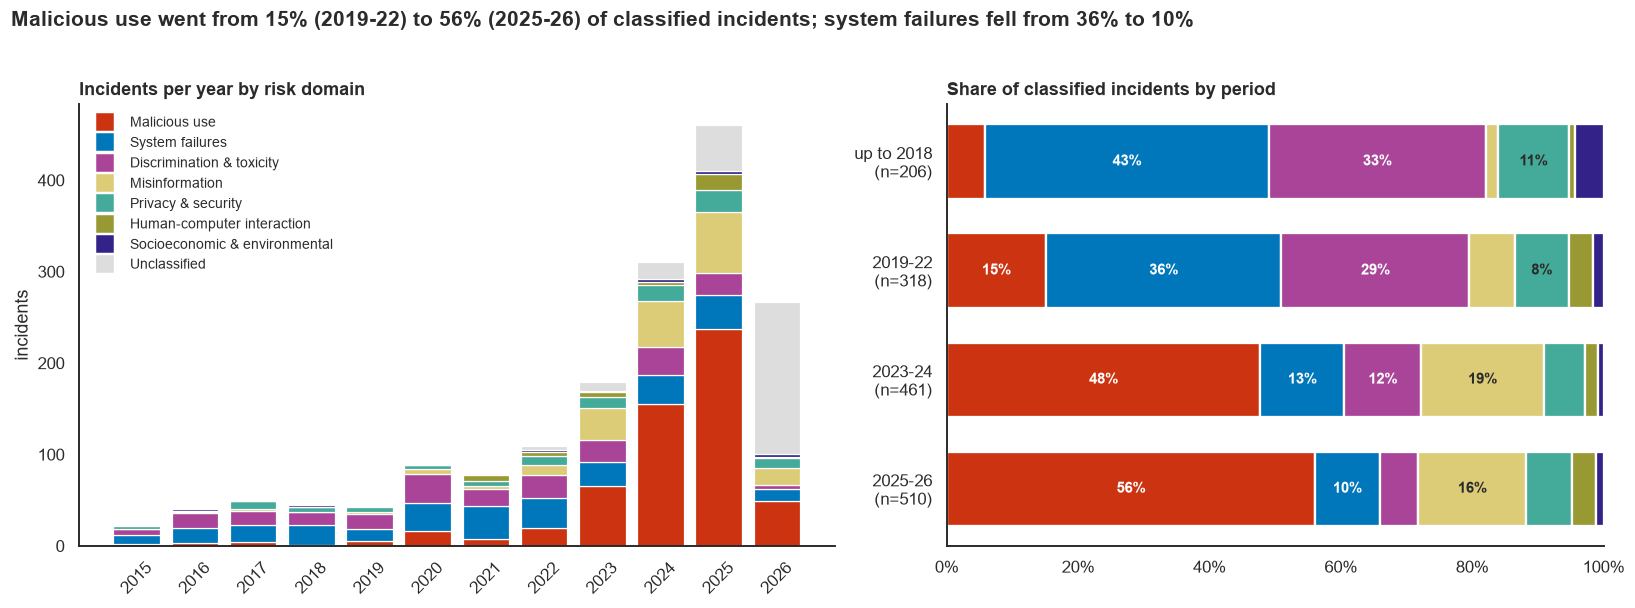

In [97]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.15, 1]})

bottom = np.zeros(len(counts))
for d in DOMAINS + ["Unclassified"]:
    ax[0].bar(counts.index, counts[d], bottom=bottom, color=DOM_COLOR[d], width=0.8, edgecolor="white", linewidth=0.8)
    bottom += counts[d].values
ax[0].set_xticks(counts.index)
ax[0].tick_params(axis="x", labelrotation=45)
ax[0].set_ylabel("incidents")
ax[0].set_title("Incidents per year by risk domain", fontsize=12)
domain_legend(ax[0], loc="upper left", fontsize=9)

y = np.arange(len(shares))[::-1]
left = np.zeros(len(shares))
for d in DOMAINS:
    ax[1].barh(y, shares[d], left=left, color=DOM_COLOR[d], height=0.68, edgecolor="white", linewidth=1.5)
    for yi, l, v in zip(y, left, shares[d]):
        if v >= 7:
            ax[1].text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=9.5, fontweight="bold",
                       color=INK if d in DARK_TEXT else "white")
    left += shares[d].values
ax[1].set_yticks(y, [f"{p}\n(n={n_period[p]})" for p in shares.index])
ax[1].set_xlim(0, 100)
ax[1].xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax[1].set_title("Share of classified incidents by period", fontsize=12)

first, last = shares.index[1], shares.index[-1]
fig.suptitle(f"Malicious use went from {shares.loc[first, 'Malicious use']:.0f}% ({first}) to {shares.loc[last, 'Malicious use']:.0f}% ({last}) "
             f"of classified incidents; system failures fell from {shares.loc[first, 'System failures']:.0f}% to {shares.loc[last, 'System failures']:.0f}%",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.02)
fig.tight_layout()
save(fig, "03_domains_over_time")
plt.show()

Left: incidents per year split by risk domain (grey = not classified yet). Right: the share of each domain among the **classified** incidents of each period, so that the unclassified backlog of 2025-26 does not distort the shares.

### 4.3 Intentional or accidental?

The MIT taxonomy also records whether the harm was intended. Below is the share of intentional incidents and of malicious use **per year with a 95% confidence interval** (Wilson interval, which works better than the normal one for small samples), only for years with at least 15 classified incidents.

In [100]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

def share_by_year(flag, min_n=15):
    g = flag.dropna().astype(float).groupby(inc["year"]).agg(["sum", "count"])
    g = g[(g.index >= 2015) & (g["count"] >= min_n)]
    g["p"] = g["sum"] / g["count"]
    g["lower bound"], g["upper bound"] = wilson(g["sum"], g["count"])
    return g

intentional = share_by_year((inc["intent_s"] == "Intentional").where(inc["intent_s"].notna()))
misuse = share_by_year((inc["domain"] == "Malicious use").where(inc["classified"]))
intentional.round(2)

,sum,count,p,lower bound,upper bound
year,,,,,
2015,5.0,24,0.21,0.09,0.40
2016,9.0,40,0.22,0.12,0.38
2017,12.0,49,0.24,0.15,0.38
2018,10.0,45,0.22,0.13,0.36
2019,13.0,43,0.30,0.19,0.45
2020,23.0,88,0.26,0.18,0.36
2021,18.0,78,0.23,0.15,0.34
2022,40.0,105,0.38,0.29,0.48
2023,89.0,168,0.53,0.45,0.60


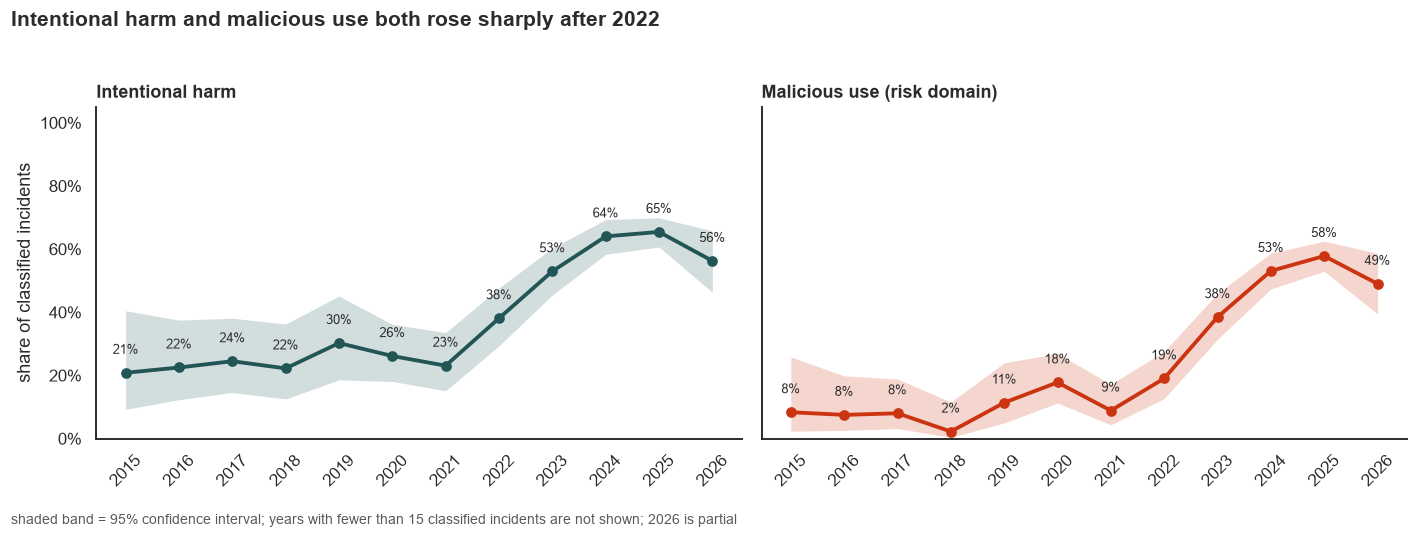

In [99]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for a, d, color, name in [(ax[0], intentional, CMP_A, "Intentional harm"),
                          (ax[1], misuse, DOM_COLOR["Malicious use"], "Malicious use (risk domain)")]:
    a.fill_between(d.index, d["lo"], d["hi"], color=color, alpha=0.2, linewidth=0)
    a.plot(d.index, d["p"], color=color, lw=2.5, marker="o")
    for x, v in d["p"].items():
        a.text(x, v + 0.06, f"{v:.0%}", ha="center", fontsize=8.5)
    a.set_xticks(d.index)
    a.tick_params(axis="x", labelrotation=45)
    a.set_ylim(0, 1.05)
    a.set_title(name, fontsize=12)
ax[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax[0].set_ylabel("share of classified incidents")
fig.suptitle("Intentional harm and malicious use both rose sharply after 2022", x=0.01, ha="left",
             fontsize=13.5, fontweight="bold", y=1.03)
fig.text(0.01, -0.03, "shaded band = 95% confidence interval; years with fewer than 15 classified incidents are not shown; 2026 is partial",
         fontsize=9, color="#5A5A5A")
fig.tight_layout()
save(fig, "04_intent_misuse_trend")
plt.show()

### 4.4 Which kinds of harm sit behind the shift?

The subdomains show what the harm is. Each cell is the share of that subdomain among the classified incidents of the period; the coloured square shows the risk domain it belongs to.

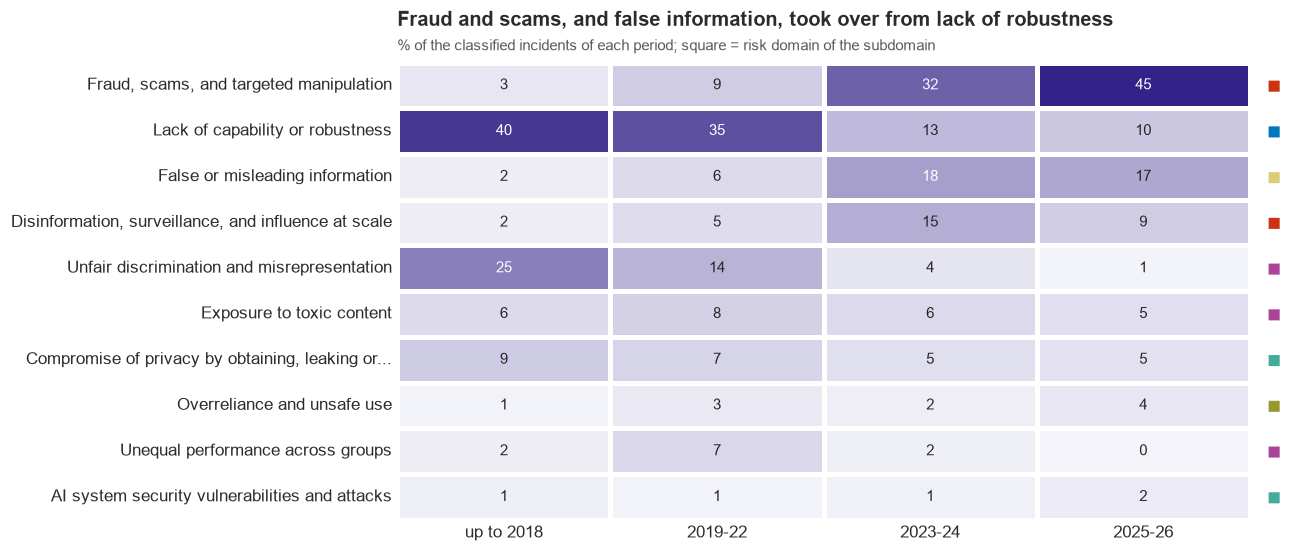

In [101]:
top_sub = inc["subdomain"].value_counts().head(10).index
heat = (pd.crosstab(inc["subdomain"], inc["period"], normalize="columns") * 100).loc[top_sub]
dom_of = inc.dropna(subset=["subdomain"]).groupby("subdomain")["dom_label"].agg(lambda s: s.mode()[0])

fig, ax = plt.subplots(figsize=(10, 5.4))
sns.heatmap(heat, annot=True, fmt=".0f", cmap=SEQ, cbar=False, ax=ax, linewidths=2, linecolor="white",
            yticklabels=[textwrap.shorten(s, 55, placeholder="...") for s in heat.index], annot_kws={"fontsize": 10})
for i, s in enumerate(heat.index):
    ax.text(len(heat.columns) + 0.08, i + 0.5, "■", color=DOM_COLOR[dom_of[s]], fontsize=16, va="center")
ax.tick_params(length=0)
ax.set_xlabel("")
ax.set_ylabel("")
titles(ax, "Fraud and scams, and false information, took over from lack of robustness",
       "% of the classified incidents of each period; square = risk domain of the subdomain")
save(fig, "05_subdomain_heatmap")
plt.show()

## 5. Who deploys, who builds, who is harmed?

### 5.1 Named organisations and generic actors

The deployer and developer fields mix two kinds of names: real organisations (*Meta*, *OpenAI*, *Tesla*) and generic descriptions of actors (*Scammers*, *Deepfake Technology Developers*). Counting them together would compare things that are not comparable.

In [102]:
for col in ["deployer_list", "developer_list"]:
    top = inc[col].explode().value_counts().head(12)
    print(f"{col}: " + ", ".join(f"{k} ({v})" for k, v in top.items()))

deployer_list: Scammers (238), Unknown actor (181), Deepfake Creators (124), Synthetic Media Creators (98), Meta (92), Openai (82), Information Manipulation Actors (73), Google (63), Tesla (43), Law Enforcement (40), Cybercriminals (39), Microsoft (30)
developer_list: Deepfake Technology Developers (448), Synthetic Audio Generation Technology Developers (238), Openai (190), Large Language Model Developers (133), Synthetic Media Generation Technology Developers (128), Synthetic Image Generation Technology Developers (122), Unknown actor (113), Meta (98), Google (97), Chatbot Developers (69), Generative Ai Developers (66), Synthetic Video Generation Technology Developers (53)


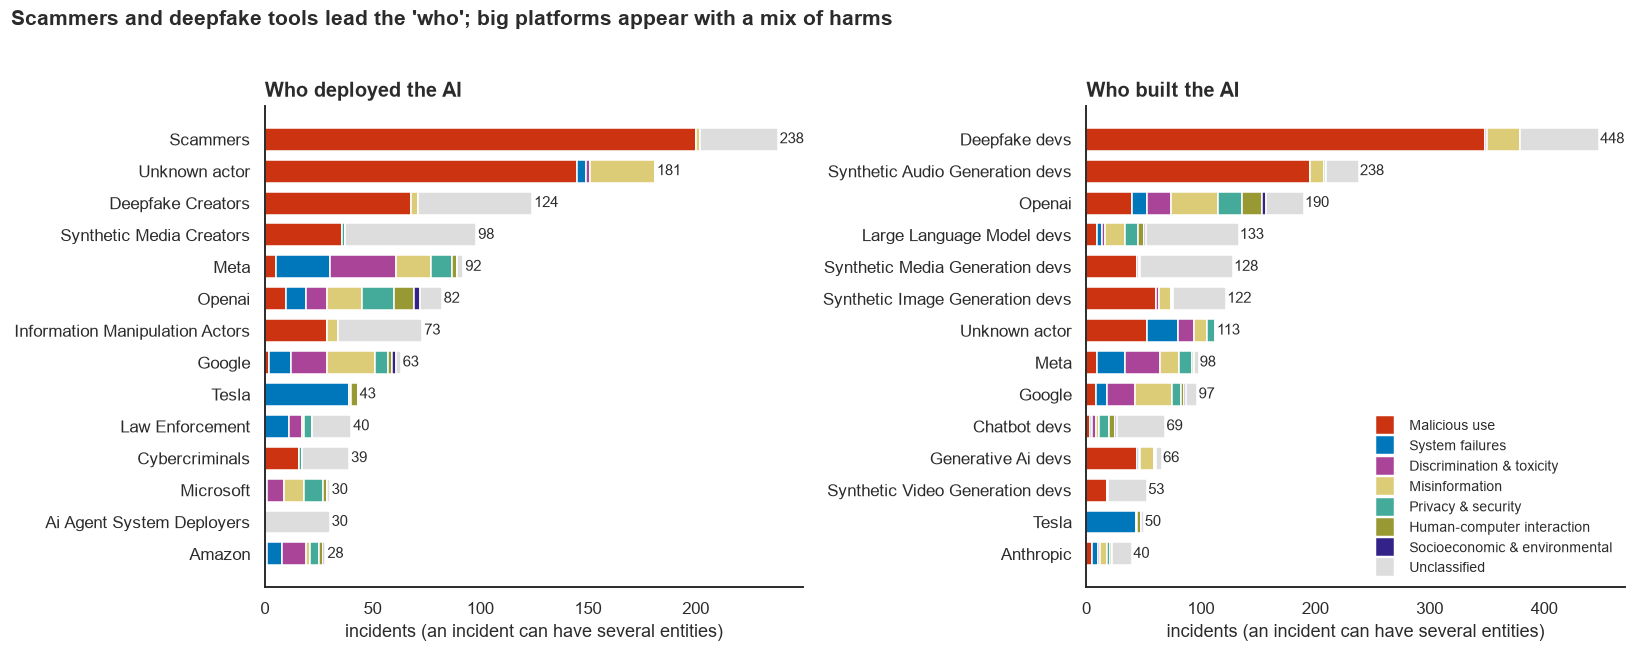

In [107]:
def top_entities(col, n=14):
    ex = inc[["id", "dom_label", col]].explode(col).dropna(subset=[col]).reset_index(drop=True)
    top = ex[col].value_counts().head(n).index
    return pd.crosstab(ex[ex[col].isin(top)][col], ex[ex[col].isin(top)].dom_label).reindex(columns=DOMAINS + ["Unclassified"], fill_value=0)

SHORT = lambda s: textwrap.shorten(s.replace(" Technology Developers", " devs").replace(" Developers", " devs"), 34, placeholder="…")
fig, ax = plt.subplots(1, 2, figsize=(15, 5.8))
for axi, col, ttl in [(ax[0], "deployer_list", "Who deployed the AI"), (ax[1], "developer_list", "Who built the AI")]:
    t = top_entities(col)
    t = t.loc[t.sum(1).sort_values().index]
    left = np.zeros(len(t))
    for d in DOMAINS + ["Unclassified"]:
        axi.barh([SHORT(i) for i in t.index], t[d], left=left, color=DOM_COLOR[d], height=0.72, edgecolor="white", linewidth=1)
        left += t[d].values
    for y, v in enumerate(t.sum(1).values):
        axi.text(v + 1, y, f"{v}", va="center", fontsize=9.5)
    axi.set_title(ttl)
    axi.set_xlabel("incidents (an incident can have several entities)")
domain_legend(ax[1], loc="lower right", fontsize=9)
fig.suptitle("Scammers and deepfake tools lead the 'who'; big platforms appear with a mix of harms",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.02)
fig.tight_layout()
save(fig, "06_deployers_developers")
plt.show()

The most frequent deployers and developers are generic actors, not companies. We mark a name as **generic** when it describes a type of actor (a plural like *Scammers*, *Developers*, *Users*, or *Unknown actor*) and as **named** otherwise.

In [103]:
GENERIC = (r"\b(developers|deployers|creators|actors|scammers|spreaders|cybercriminals|criminals|fraudsters|hackers|"
           r"operators|users|students|boys|men|women|minors|lawyers|law firms|stalkers|perpetrators|departments|"
           r"enforcement|individuals|people|groups|companies|platforms|employers|attackers|accounts|teenagers|parents)\b"
           r"|technology$|^unknown actor$")

def actor_kind(name):
    return "generic" if re.search(GENERIC, name, re.I) else "named"

actors = pd.concat([inc["deployer_list"].explode(), inc["developer_list"].explode()]).dropna()
kinds = actors.map(actor_kind)
for k in ["named", "generic"]:
    top = actors[kinds == k].value_counts().head(15)
    print(f"{k} ({(kinds == k).mean():.0%} of mentions): " + ", ".join(top.index))

named (55% of mentions): Openai, Meta, Google, Tesla, Microsoft, Amazon, Xai, Anthropic, Waymo, X (Twitter), Apple, Youtube, Tiktok, Cruise, Instagram
generic (45% of mentions): Deepfake Technology Developers, Unknown actor, Synthetic Audio Generation Technology Developers, Scammers, Deepfake Creators, Large Language Model Developers, Synthetic Media Generation Technology Developers, Synthetic Image Generation Technology Developers, Synthetic Media Creators, Information Manipulation Actors, Chatbot Developers, Generative Ai Developers, Synthetic Video Generation Technology Developers, Law Enforcement, Cybercriminals


The split works well for the frequent names. A few edge cases remain (e.g. *Government Of Russia* counts as named, *Law Enforcement* as generic), which is fine for our purpose.

### 5.2 From companies to anonymous actors

For every incident we ask two separate questions: is any **real organisation** named as the one who *used* the AI (deployer), and is any real organisation named as the one who *built* it (developer)? If the field only contains types of actors, such as "Scammers", "Deepfake Technology Developers" or "Unknown actor", we count the incident as **only generic**. An incident like "Scammers, Meta" is not only generic, because Meta is a real company.

In [106]:
def only_generic(names):
    return len(names) > 0 and all(actor_kind(n) == "generic" for n in names)

anon = pd.DataFrame({"deployer": inc["deployer_list"].map(only_generic),
                     "developer": inc["developer_list"].map(only_generic)})
anon_share = anon.groupby(inc["period"], observed=True).mean() * 100
anon_share.round(0)

,deployer,developer
period,,
up to 2018,1.0,8.0
2019-22,6.0,17.0
2023-24,24.0,41.0
2025-26,31.0,56.0


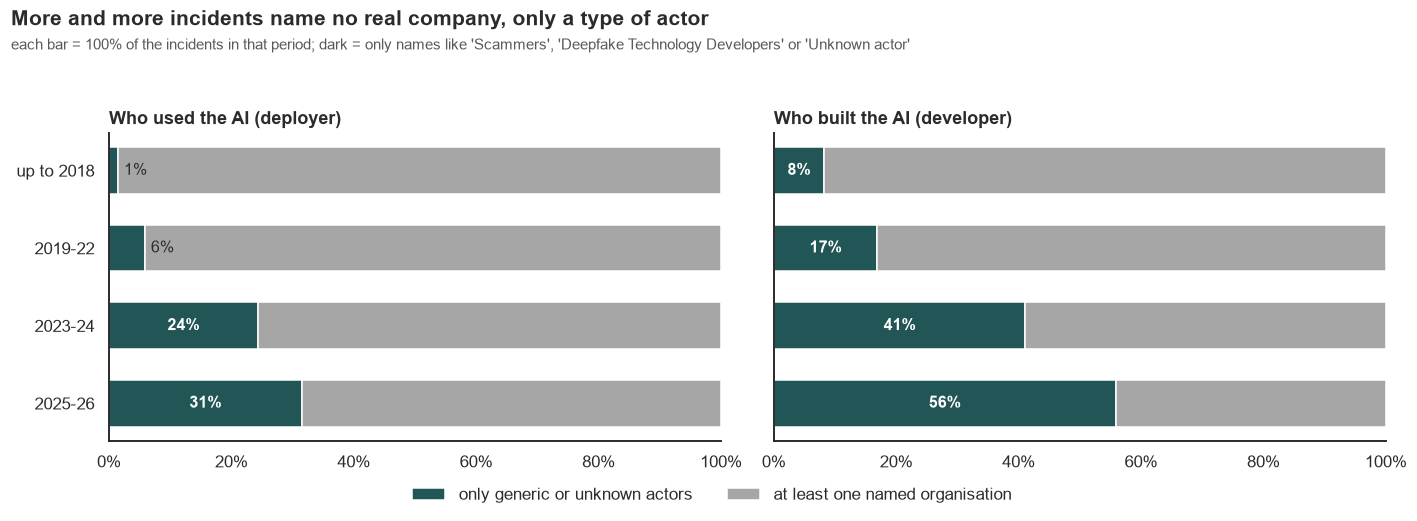

In [113]:
anon_share = anon.groupby(inc["period"], observed=True).mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
y = np.arange(len(anon_share))[::-1]
for a, col, name in [(ax[0], "deployer", "Who used the AI (deployer)"), (ax[1], "developer", "Who built the AI (developer)")]:
    generic = anon_share[col]
    a.barh(y, generic, color=CMP_A, height=0.6, label="only generic or unknown actors")
    a.barh(y, 100 - generic, left=generic, color=CMP_B, height=0.6, label="at least one named organisation")
    for yi, v in zip(y, generic):
        if v >= 8:
            a.text(v / 2, yi, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=10.5, fontweight="bold")
        else:
            a.text(v + 1, yi, f"{v:.0f}%", va="center", fontsize=10.5)
    a.set_xlim(0, 100)
    a.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    a.set_title(name, fontsize=12)
ax[0].set_yticks(y, anon_share.index)
fig.suptitle("More and more incidents name no real company, only a type of actor", x=0.01, ha="left",
             fontsize=13.5, fontweight="bold", y=1.04)
fig.text(0.01, 0.955, "each bar = 100% of the incidents in that period; dark = only names like 'Scammers', "
         "'Deepfake Technology Developers' or 'Unknown actor'", fontsize=9.5, color="#5A5A5A")
fig.legend(*ax[0].get_legend_handles_labels(), loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "06a_generic_actors_by_period")
plt.show()

Up to 2018 almost every incident names a real company, both as user and as builder of the AI. In 2025-26, a third of incidents only say that "some scammers" or "someone unknown" used the AI, and more than half do not name the company that built it, only the type of tool ("deepfake technology"). The harm increasingly comes from anonymous people using widely available tools, not from one identifiable system of one company.


### 5.3 Which organisations and which actor types appear most often?

An incident counts for an organisation if it is the deployer or the developer (or both). Colours show the risk domain of the incidents.

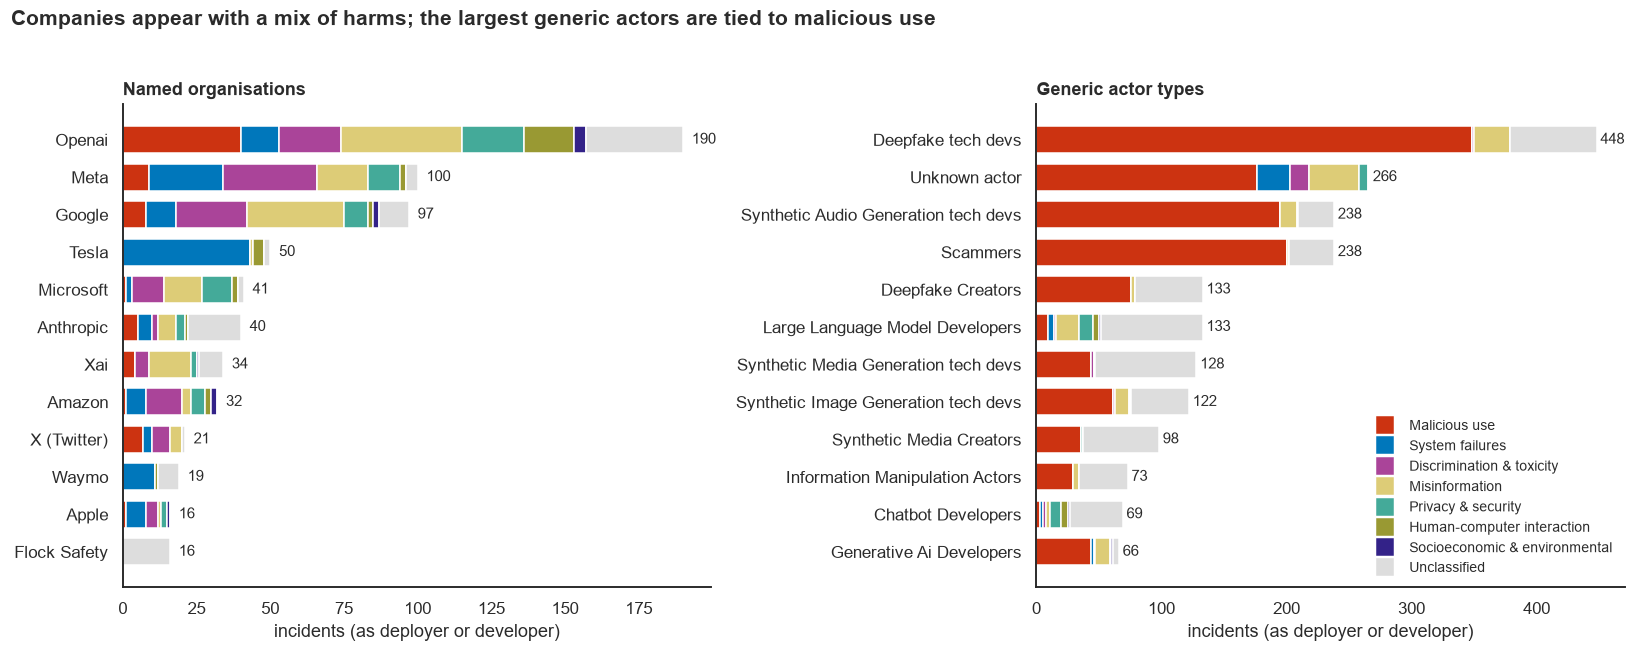

In [114]:
long = inc[["id", "dom_label"]].assign(actor=inc["deployer_list"] + inc["developer_list"]).explode("actor", ignore_index=True).dropna()
long = long.drop_duplicates(["id", "actor"])
long["kind"] = long["actor"].map(actor_kind)

def top_by_domain(kind, n=12):
    sub = long[long["kind"] == kind]
    top = sub["actor"].value_counts().head(n).index
    table = pd.crosstab(sub[sub["actor"].isin(top)]["actor"], sub["dom_label"])
    table = table.reindex(columns=DOMAINS + ["Unclassified"], fill_value=0)
    return table.loc[table.sum(axis=1).sort_values().index]

short = lambda s: textwrap.shorten(s.replace(" Technology Developers", " tech devs"), 36, placeholder="...")

fig, ax = plt.subplots(1, 2, figsize=(15, 5.8))
for a, kind, name in [(ax[0], "named", "Named organisations"), (ax[1], "generic", "Generic actor types")]:
    t = top_by_domain(kind)
    left = np.zeros(len(t))
    for d in DOMAINS + ["Unclassified"]:
        a.barh([short(i) for i in t.index], t[d], left=left, color=DOM_COLOR[d], height=0.72, edgecolor="white", linewidth=1)
        left += t[d].values
    for y, v in enumerate(t.sum(axis=1)):
        a.text(v + 3, y, f"{v}", va="center", fontsize=9.5)
    a.set_title(name, fontsize=12)
    a.set_xlabel("incidents (as deployer or developer)")
domain_legend(ax[1], loc="lower right", fontsize=9)
fig.suptitle("Companies appear with a mix of harms; the largest generic actors are tied to malicious use",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.02)
fig.tight_layout()
save(fig, "06_deployers_developers")
plt.show()

### 5.4 How deployers and developers are linked

A matrix instead of a network: drawn as nodes and links, these pairs become an unreadable hairball, while a matrix shows every pair at once. Rows are the 12 most frequent deployers, columns the 12 most frequent developers, numbers are incidents.

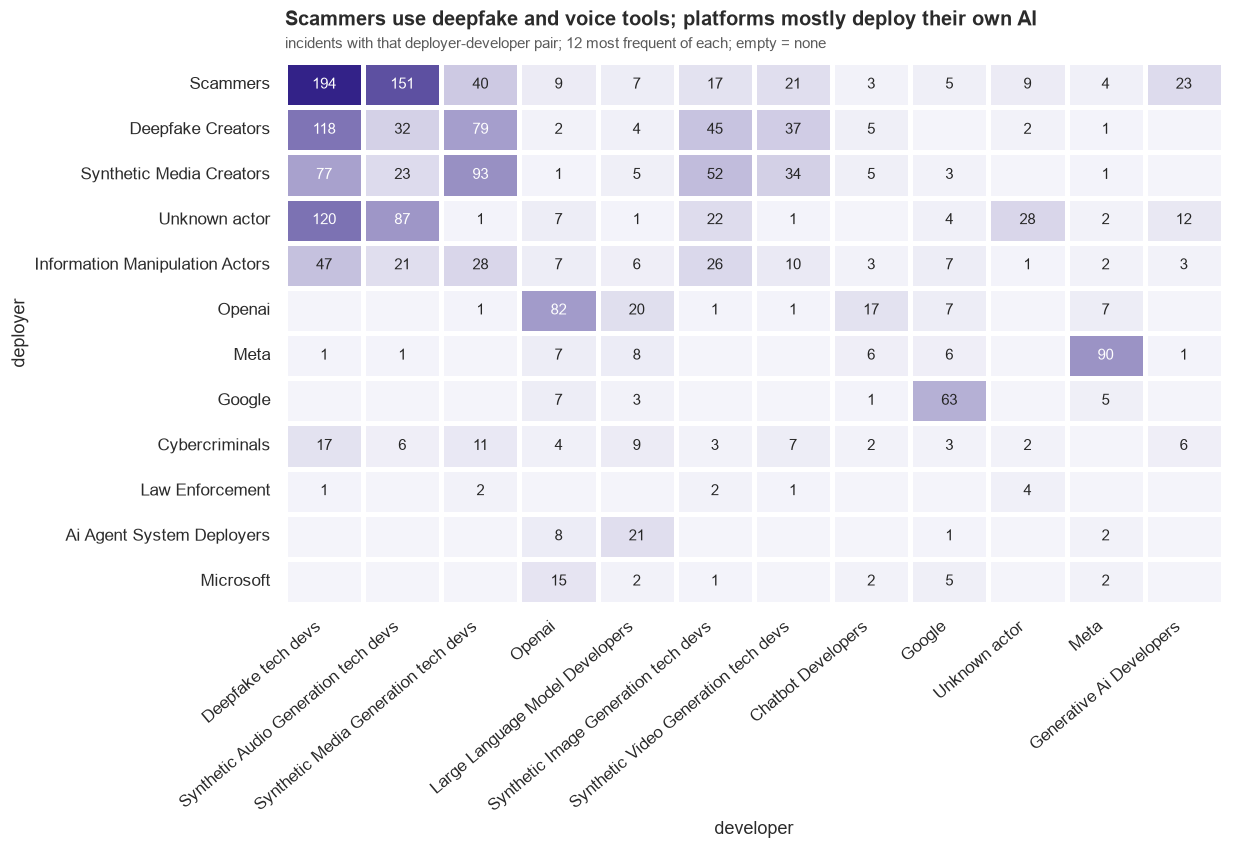

In [115]:
pairs = inc[["deployer_list", "developer_list"]].explode("deployer_list").explode("developer_list").dropna()
pairs.columns = ["deployer", "developer"]
top_dep = pairs["deployer"].value_counts().head(12).index
top_dev = pairs["developer"].value_counts().head(12).index
matrix = (pairs[pairs["deployer"].isin(top_dep) & pairs["developer"].isin(top_dev)]
          .value_counts().unstack(fill_value=0).reindex(index=top_dep, columns=top_dev, fill_value=0))

fig, ax = plt.subplots(figsize=(11, 6.4))
sns.heatmap(matrix, annot=matrix.where(matrix > 0, ""), fmt="", cmap=SEQ, cbar=False, linewidths=2, linecolor="white",
            ax=ax, annot_kws={"fontsize": 9.5})
ax.set_xticklabels([short(t.get_text()) for t in ax.get_xticklabels()], rotation=40, ha="right")
ax.set_yticklabels([short(t.get_text()) for t in ax.get_yticklabels()], rotation=0)
ax.set_xlabel("developer")
ax.set_ylabel("deployer")
titles(ax, "Scammers use deepfake and voice tools; platforms mostly deploy their own AI",
       "incidents with that deployer-developer pair; 12 most frequent of each; empty = none")
save(fig, "07_deployer_developer_links")
plt.show()

### 5.5 Who is harmed by which type of harm?

Using the harmed groups from section 2.6: for each group, how its classified incidents split across the risk domains.

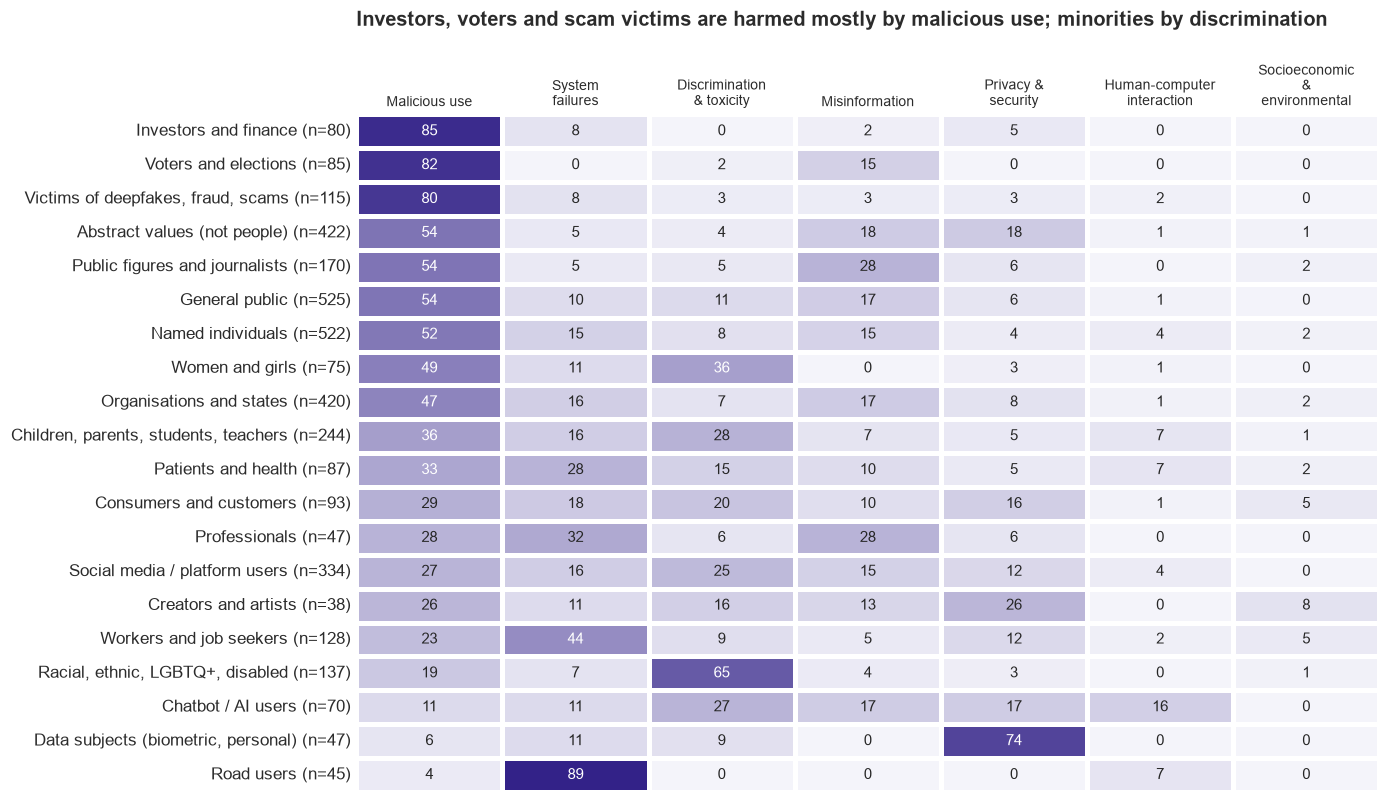

In [118]:
hg = inc.loc[inc["classified"], ["harmed_groups", "dom_label"]].explode("harmed_groups", ignore_index=True)
hg = hg[hg["harmed_groups"] != "Not grouped"]
top_groups = hg["harmed_groups"].value_counts().head(20).index
by_domain = pd.crosstab(hg["harmed_groups"], hg["dom_label"], normalize="index").reindex(index=top_groups, columns=DOMAINS) * 100
by_domain = by_domain.sort_values("Malicious use", ascending=False)
n_group = hg["harmed_groups"].value_counts()

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(by_domain, annot=True, fmt=".0f", cmap=SEQ, cbar=False, linewidths=2, linecolor="white", ax=ax,
            yticklabels=[f"{g} (n={n_group[g]})" for g in by_domain.index], annot_kws={"fontsize": 9.5})
ax.set_xticklabels([textwrap.fill(t.get_text(), 14) for t in ax.get_xticklabels()], rotation=0, fontsize=9)
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Investors, voters and scam victims are harmed mostly by malicious use; minorities by discrimination", pad=58)
save(fig, "08_harmed_by_domain")
plt.show()

## 6. What gets covered: `report_count`

`report_count` is the number of news articles linked to an incident. It tells us how much media attention an incident got.

### 6.1 How many reports does an incident get?

In [119]:
print(inc["report_count"].describe().round(1))
print(f"Incidents with 0 reports: {(inc['report_count'] == 0).sum()}, with more than 20: {(inc['report_count'] > 20).sum()}")

count    1748.0
mean        3.9
std         6.0
min         0.0
25%         1.0
50%         2.0
75%         4.0
max        58.0
Name: report_count, dtype: float64
Incidents with 0 reports: 1, with more than 20: 68


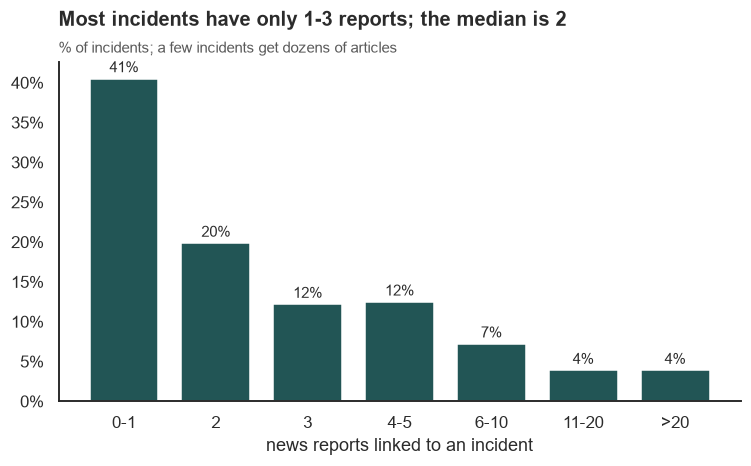

In [120]:
bins = pd.cut(inc["report_count"], [-1, 1, 2, 3, 5, 10, 20, 100],
              labels=["0-1", "2", "3", "4-5", "6-10", "11-20", ">20"])
dist = bins.value_counts(normalize=True).reindex(bins.cat.categories) * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dist.index, dist.values, color=CMP_A, width=0.75)
for x, v in enumerate(dist.values):
    ax.text(x, v + 0.8, f"{v:.0f}%", ha="center", fontsize=10)
ax.set_xlabel("news reports linked to an incident")
ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
titles(ax, f"Most incidents have only 1-3 reports; the median is {inc['report_count'].median():.0f}",
       "% of incidents; a few incidents get dozens of articles")
save(fig, "09a_report_count_distribution")
plt.show()

The distribution is very skewed: half of the incidents have two reports or fewer, a few have more than 20. So for comparisons we use the **median** and a rank-based test, not the mean.

### 6.2 Does coverage depend on the type of harm?

We compare the number of reports across the seven risk domains with the **Kruskal-Wallis test** (the rank-based version of a one-way ANOVA, fine for skewed counts). The p-value says whether the domains differ at all; the effect size **epsilon-squared** says how much (0 = no difference, 1 = the domain explains everything; around 0.01 is small, 0.08 medium, 0.26 large).

In [121]:
from scipy import stats

cls = inc[inc["classified"]]
groups = [g["report_count"].values for _, g in cls.groupby("domain", observed=True)]
kw = stats.kruskal(*groups)
eps2 = (kw.statistic - len(groups) + 1) / (len(cls) - len(groups))

print(f"Kruskal-Wallis: H = {kw.statistic:.1f}, p = {kw.pvalue:.4f}, epsilon-squared = {eps2:.3f}")
cls.groupby("domain", observed=True)["report_count"].agg(["count", "median", "mean"]).round(1)

Kruskal-Wallis: H = 38.5, p = 0.0000, epsilon-squared = 0.022


,count,median,mean
domain,,,
Malicious use,566,2.0,3.6
System failures,312,2.0,4.8
Discrimination & toxicity,243,2.0,4.4
Misinformation,196,2.0,3.7
Privacy & security,112,2.0,4.1
Human-computer interaction,42,2.0,5.2
Socioeconomic & environmental,24,3.0,5.9


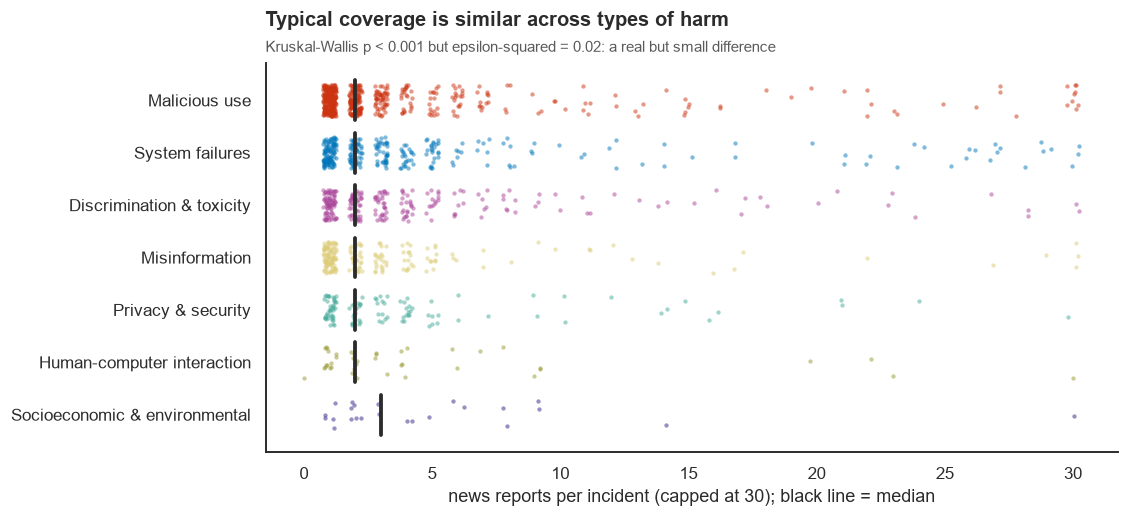

In [122]:
rng = np.random.default_rng(SEED)
medians = cls.groupby("domain", observed=True)["report_count"].median()

fig, ax = plt.subplots(figsize=(10, 4.6))
for k, d in enumerate(DOMAINS):
    v = cls.loc[cls["domain"] == d, "report_count"].clip(upper=30)
    ax.scatter(v + rng.uniform(-0.25, 0.25, len(v)), k + rng.uniform(-0.3, 0.3, len(v)),
               s=8, color=DOM_COLOR[d], alpha=0.5, linewidths=0)
    ax.plot([medians[d]] * 2, [k - 0.38, k + 0.38], color=INK, lw=2.5)
ax.set_yticks(range(len(DOMAINS)), DOMAINS)
ax.invert_yaxis()
ax.set_xlabel("news reports per incident (capped at 30); black line = median")
titles(ax, "Typical coverage is similar across types of harm",
       f"Kruskal-Wallis p < 0.001 but epsilon-squared = {eps2:.2f}: a real but small difference")
save(fig, "09_report_counts")
plt.show()

The test is significant (p < 0.001), but the effect is small (epsilon-squared = 0.02): with 1,500 incidents even tiny differences become "significant", so the effect size is the more useful number. The median is 2 reports in almost every domain. If anything, malicious use gets slightly *fewer* reports per incident than system failures (mean 3.6 vs 4.8), so its rise in the database is not because each misuse incident gets more media attention.

### 6.3 The incidents that made the biggest headlines

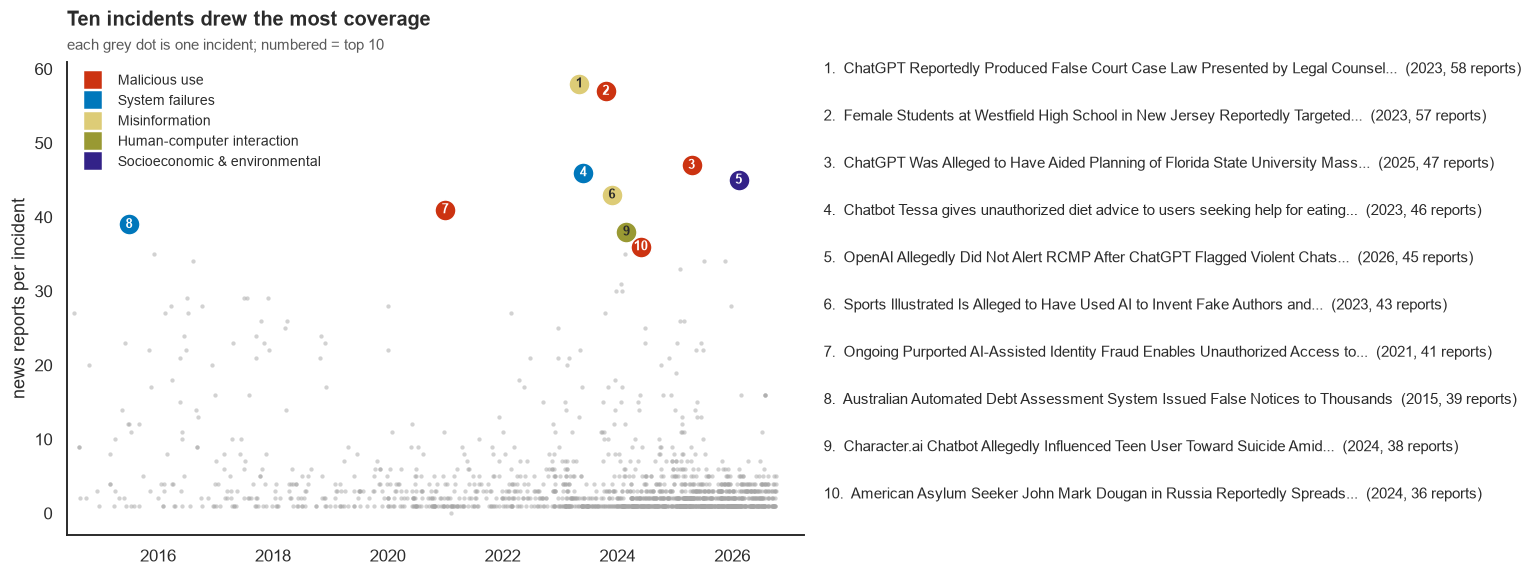

In [123]:
top = inc.nlargest(10, "report_count").reset_index(drop=True)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.15, 1]})
ax.scatter(inc["date"], inc["report_count"], s=8, color=CMP_B, alpha=0.5, linewidths=0)
for i, r in top.iterrows():
    ax.scatter(r["date"], r["report_count"], s=190, color=DOM_COLOR[r["dom_label"]], zorder=3, edgecolor="white")
    ax.text(r["date"], r["report_count"], str(i + 1), ha="center", va="center", fontsize=8.5, zorder=4,
            color=INK if r["dom_label"] in DARK_TEXT else "white", fontweight="bold")
ax.set_xlim(pd.Timestamp("2014-06-01"), pd.Timestamp("2027-04-01"))
ax.set_ylabel("news reports per incident")
domain_legend(ax, names=[d for d in DOMAINS if d in set(top["dom_label"])], loc="upper left", fontsize=9)
titles(ax, "Ten incidents drew the most coverage", "each grey dot is one incident; numbered = top 10")

ax2.axis("off")
for i, r in top.iterrows():
    ax2.text(0, 1 - i * 0.1, f"{i + 1}.  {textwrap.shorten(r['title'], 80, placeholder='...')}  "
             f"({r['date'].year}, {r['report_count']} reports)", fontsize=9.5, va="top", transform=ax2.transAxes)
fig.tight_layout()
save(fig, "10_top_incidents_timeline")
plt.show()

## 7. The media lens: the 7,955 news reports

The reports are the evidence behind the incidents. We cannot join them to incidents, but they describe **how AI harm is covered**: when, by whom and under which themes.

### 7.1 Volume and sources

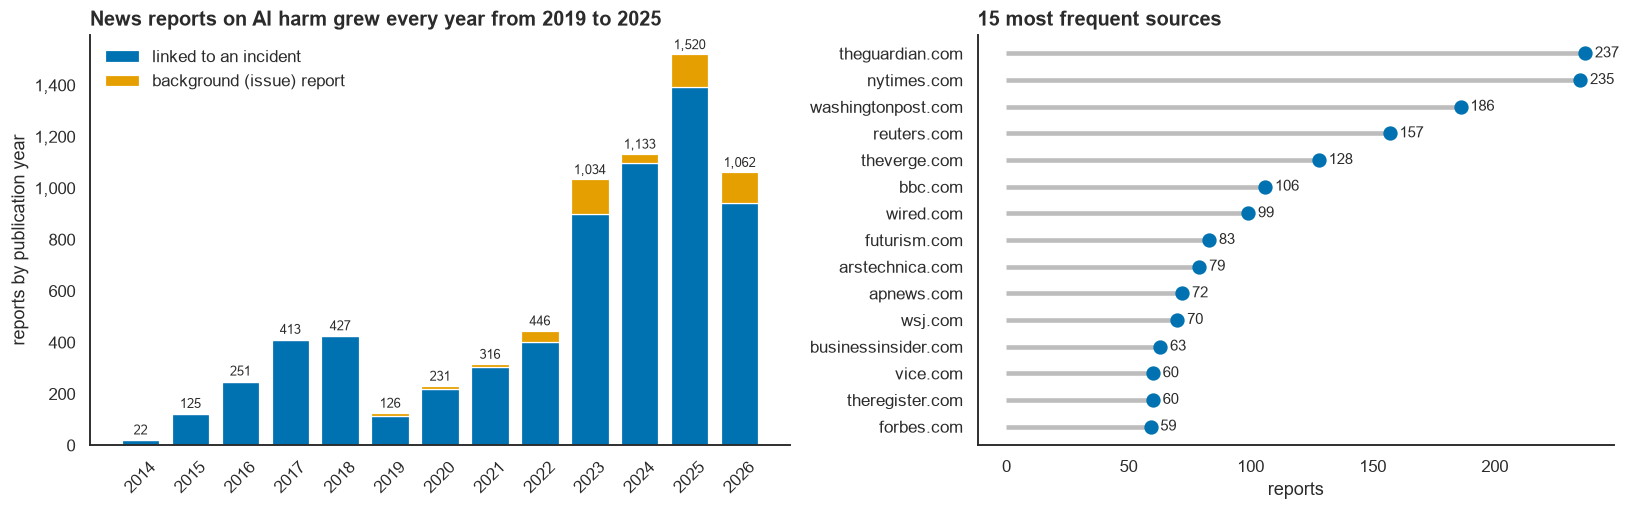

2,177 different source domains; the 10 most frequent hold 19% of the reports with a known source. Languages: 96% English. One submitter (Daniel Atherton) contributed 50% of all reports.


In [15]:
rep = rep_raw.copy()
rep["pub"] = pd.to_datetime(rep["Date Published"], errors="coerce")
rep["year"] = rep.pub.dt.year
rep["text"] = (rep.Title.fillna("") + ". " + rep.Description.fillna("")).str.strip(". ").str.strip()
rep["is_inc"] = rep["Is Incident Report"].map({True: "linked to an incident", False: "background (issue) report"})

by_year = rep[rep.year >= 2014].groupby(["year", "is_inc"]).size().unstack(fill_value=0)
src = rep["Source Domain"].value_counts()
subm = rep["Submitters"].astype(str).value_counts()
top10_share = src.head(10).sum() / src.sum()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
bottom = np.zeros(len(by_year))
for col, color in [("linked to an incident", BLUE), ("background (issue) report", ORANGE)]:
    if col in by_year:
        ax[0].bar(by_year.index, by_year[col], bottom=bottom, color=color, width=0.75, edgecolor="white", linewidth=0.8, label=col)
        bottom += by_year[col].values
for x, v in zip(by_year.index, bottom):
    ax[0].text(x, v + 20, f"{int(v):,}", ha="center", fontsize=8.5)
ax[0].set_xticks(by_year.index)
ax[0].tick_params(axis="x", labelrotation=45)
ax[0].yaxis.set_major_formatter(thousands)
ax[0].set_ylabel("reports by publication year")
ax[0].legend(loc="upper left")
ax[0].set_title("News reports on AI harm grew every year from 2019 to 2025")

t = src.head(15)[::-1]
ax[1].hlines(t.index, 0, t.values, color=GREY, lw=3)
ax[1].scatter(t.values, t.index, color=BLUE, s=70, zorder=3)
for y, v in enumerate(t.values):
    ax[1].text(v + 4, y, f"{v}", va="center", fontsize=9.5)
ax[1].set_xlabel("reports")
ax[1].set_title("15 most frequent sources")
fig.tight_layout()
save(fig, "11_reports_volume_sources")
plt.show()
print(f"{src.size:,} different source domains; the 10 most frequent hold {top10_share:.0%} of the reports with a known source. "
      f"Languages: {rep.Language.value_counts(normalize=True).iloc[0]:.0%} English. "
      f"One submitter ({subm.index[0]}) contributed {subm.iloc[0] / len(rep):.0%} of all reports.")

### 7.2 What the media talks about: transparent keyword themes

Before topic modelling, a simple and fully transparent view: the share of report titles that mention a theme, by year. Each theme is a short list of words (written below), so anyone can check what is counted.

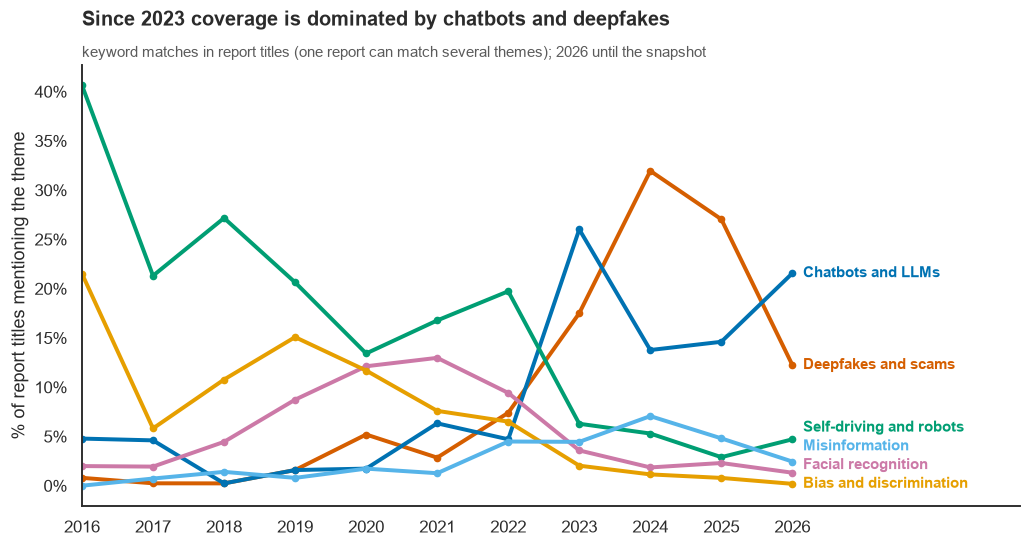

,words counted
Deepfakes and scams,deepfake|scam|fraud|impersonat|voice clon|synthetic
Chatbots and LLMs,chatgpt|chatbot|openai|gemini|llm|language model|grok|copilot|claude|character\.ai|replika
Self-driving and robots,tesla|waymo|cruise|self-driving|autopilot|autonomous|driverless|robotaxi|robot
Facial recognition,facial recognition|face recognition|clearview|surveillance|biometric
Bias and discrimination,bias|discriminat|racis|sexis|gender|unfair
Misinformation,misinformation|disinformation|fake news|false information|election|hallucinat


In [17]:
THEMES = {"Deepfakes and scams": r"deepfake|scam|fraud|impersonat|voice clon|synthetic",
          "Chatbots and LLMs": r"chatgpt|chatbot|openai|gemini|llm|language model|grok|copilot|claude|character\.ai|replika",
          "Self-driving and robots": r"tesla|waymo|cruise|self-driving|autopilot|autonomous|driverless|robotaxi|robot",
          "Facial recognition": r"facial recognition|face recognition|clearview|surveillance|biometric",
          "Bias and discrimination": r"bias|discriminat|racis|sexis|gender|unfair",
          "Misinformation": r"misinformation|disinformation|fake news|false information|election|hallucinat"}
titles = rep[rep.year.between(2016, 2026)].copy()
titles["t"] = titles.Title.fillna("").str.lower()
yr_n = titles.groupby("year").size()
share = pd.DataFrame({k: titles.groupby("year").t.apply(lambda s: s.str.contains(v, regex=True).mean())
                      for k, v in THEMES.items()}) * 100
theme_color = dict(zip(THEMES, ["#D55E00", "#0072B2", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]))

fig, ax = plt.subplots(figsize=(11, 5.2))
ends = share.iloc[-1].sort_values()
ypos, last = {}, -99
for k, v in ends.items():
    last = max(v, last + 1.9)
    ypos[k] = last
for k in THEMES:
    ax.plot(share.index, share[k], color=theme_color[k], lw=2.6, marker="o", markersize=4)
    ax.text(share.index[-1] + 0.15, ypos[k], k, color=theme_color[k], fontsize=10, va="center", fontweight="bold")
ax.set_xlim(2016, 2029.2)
ax.set_xticks(range(2016, 2027))
ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.set_ylabel("% of report titles mentioning the theme")
ax.set_title("Since 2023 coverage is dominated by chatbots and deepfakes")
subtitle(ax, "keyword matches in report titles (one report can match several themes); 2026 until the snapshot", y=1.0)
ax.set_title(ax._left_title.get_text(), pad=26)
save(fig, "12_media_themes")
plt.show()
display(pd.Series({k: v for k, v in THEMES.items()}).to_frame("words counted").style.set_properties(**{"text-align": "left"}))

## 8. Topic modelling of the incident descriptions

We compare three families of methods, because no single method is best for every purpose (*No Free Lunch*):

| Method | Idea | Strength | Weakness |
|---|---|---|---|
| **NMF** on TF-IDF | split the document-word matrix into additive topics | sharp, easy to read topics | needs the number of topics |
| **LDA** on word counts | probabilistic mixture of topics | a document can have several topics | blurrier on short texts |
| **Embeddings + clustering** (BERTopic style) | embed each text, reduce with UMAP, cluster with HDBSCAN | finds the number of clusters itself; uses meaning | depends on the embedding; some texts stay unassigned |

We judge them with three measures: **coherence** (do the top words of a topic occur together in documents? UMass, higher is better), **diversity** (share of distinct top words; 1 = no overlap) and **agreement with the MIT taxonomy** (normalised mutual information, NMI, on classified incidents). A topic model does not have to match the taxonomy: the comparison shows how much the *text* already contains of the official classification.

### 8.1 Choosing the number of topics

vocabulary: 2,442 words (TF-IDF), 2,442 (counts)


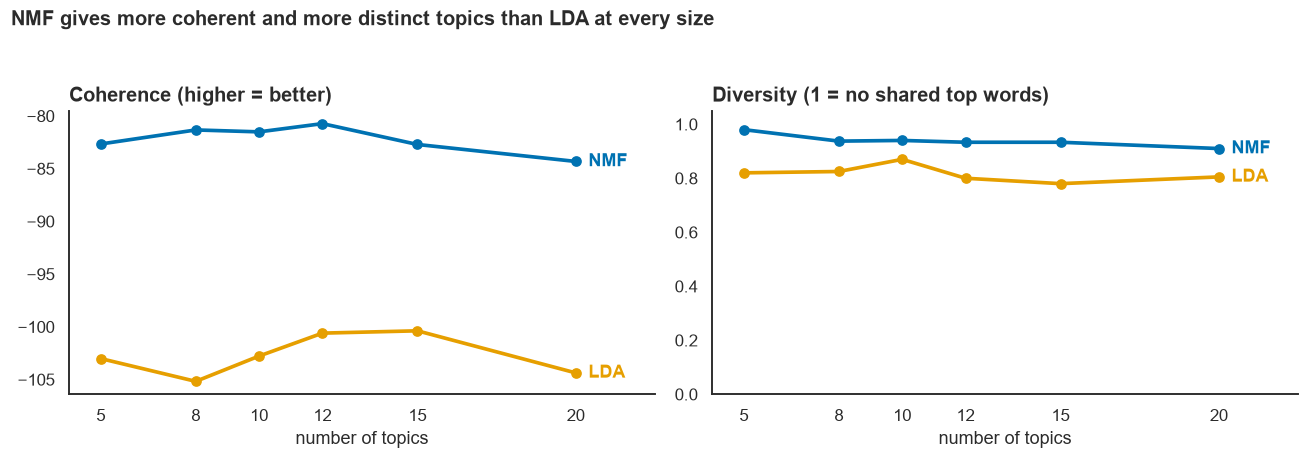

,NMF,LDA,NMF diversity,LDA diversity
k,,,,
5,-82.66,-103.02,0.98,0.82
8,-81.33,-105.18,0.94,0.82
10,-81.51,-102.77,0.94,0.87
12,-80.73,-100.60,0.93,0.80
15,-82.71,-100.38,0.93,0.78
20,-84.32,-104.37,0.91,0.80


In [18]:
STOP = list(CountVectorizer(stop_words="english").get_stop_words()) + [
    "ai", "reportedly", "allegedly", "used", "using", "use", "said", "according", "incident", "system", "systems",
    "people", "based", "generated", "created", "included", "following", "one", "two", "new", "also"]

docs = inc.text.tolist()
tfidf = TfidfVectorizer(stop_words=STOP, min_df=5, max_df=0.5, ngram_range=(1, 1), sublinear_tf=True)
X_tfidf = tfidf.fit_transform(docs)
cv = CountVectorizer(stop_words=STOP, min_df=5, max_df=0.5)
X_cnt = cv.fit_transform(docs)
vocab_t, vocab_c = np.array(tfidf.get_feature_names_out()), np.array(cv.get_feature_names_out())
print(f"vocabulary: {len(vocab_t):,} words (TF-IDF), {len(vocab_c):,} (counts)")

def top_idx(components, n=10):
    return np.argsort(-components, axis=1)[:, :n]

def umass(topics_idx, X_counts):
    B = (X_counts > 0).astype(np.int32)
    co = (B.T @ B).toarray()
    df_ = np.diag(co)
    scores = []
    for words in topics_idx:
        s = 0
        for m in range(1, len(words)):
            for l in range(m):
                s += np.log((co[words[m], words[l]] + 1) / df_[words[l]])
        scores.append(s)
    return np.mean(scores)

def diversity(topics_idx):
    return len(set(topics_idx.ravel())) / topics_idx.size

rows = []
for k in [5, 8, 10, 12, 15, 20]:
    nmf = NMF(k, init="nndsvd", random_state=SEED, max_iter=400).fit(X_tfidf)
    lda = LatentDirichletAllocation(k, learning_method="batch", max_iter=25, random_state=SEED).fit(X_cnt)
    ti_n, ti_l = top_idx(nmf.components_), top_idx(lda.components_)
    rows.append({"k": k, "NMF": umass(ti_n, X_cnt), "LDA": umass(ti_l, X_cnt),
                 "NMF diversity": diversity(ti_n), "LDA diversity": diversity(ti_l)})
sweep = pd.DataFrame(rows).set_index("k")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for col, color in [("NMF", BLUE), ("LDA", ORANGE)]:
    ax[0].plot(sweep.index, sweep[col], marker="o", lw=2.4, color=color)
    ax[0].text(sweep.index[-1] + 0.4, sweep[col].iloc[-1], col, color=color, fontweight="bold", va="center")
    ax[1].plot(sweep.index, sweep[col + " diversity"], marker="o", lw=2.4, color=color)
    ax[1].text(sweep.index[-1] + 0.4, sweep[col + " diversity"].iloc[-1], col, color=color, fontweight="bold", va="center")
ax[0].set_title("Coherence (higher = better)")
ax[1].set_title("Diversity (1 = no shared top words)")
ax[1].set_ylim(0, 1.05)
for a in ax:
    a.set_xlabel("number of topics")
    a.set_xlim(4, 22.5)
    a.set_xticks(list(sweep.index))
fig.suptitle("NMF gives more coherent and more distinct topics than LDA at every size", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout()
save(fig, "13_topic_number_sweep")
plt.show()
display(sweep.round(2))

### 8.2 The topics (NMF with the chosen number of topics)

`K_TOPICS` is set to 10 (a readable size for a 20-minute talk). Every incident is assigned to its strongest topic. The table shows the top words, the number of incidents and the **most common risk domain** within each topic.

In [19]:
K_TOPICS = 10
nmf = NMF(K_TOPICS, init="nndsvd", random_state=SEED, max_iter=500).fit(X_tfidf)
W = nmf.transform(X_tfidf)
inc["topic_nmf"] = W.argmax(1)
ti = top_idx(nmf.components_, 8)
topic_name = {k: ", ".join(vocab_t[ti[k][:4]]) for k in range(K_TOPICS)}

tab = pd.crosstab(inc.topic_nmf, inc.dom_label).reindex(columns=DOMAINS + ["Unclassified"], fill_value=0)
cls_only = tab[DOMAINS]
summary = pd.DataFrame({"top words": [", ".join(vocab_t[ti[k]]) for k in range(K_TOPICS)],
                        "incidents": tab.sum(1),
                        "main domain": cls_only.idxmax(1),
                        "its share of classified": (cls_only.max(1) / cls_only.sum(1) * 100).round(0).astype(int).astype(str) + "%"})
display(summary.sort_values("incidents", ascending=False))

,top words,incidents,main domain,its share of classified
topic_nmf,,,,
1,"data, google, chatgpt, openai, user, reported,...",329,Privacy & security,23%
7,"facebook, content, moderation, automated, algo...",216,Discrimination & toxicity,46%
4,"images, school, students, student, explicit, c...",208,Malicious use,60%
5,"video, purported, deepfake, president, trump, ...",184,Malicious use,68%
9,"campaign, media, disinformation, videos, elect...",181,Malicious use,76%
0,"scam, deepfake, investment, voice, scammers, 0...",171,Malicious use,99%
6,"court, citations, legal, case, chatgpt, attorn...",148,Misinformation,49%
8,"autonomous, waymo, san, vehicle, francisco, dr...",139,System failures,86%
3,"facial, recognition, police, black, arrest, te...",118,Discrimination & toxicity,37%


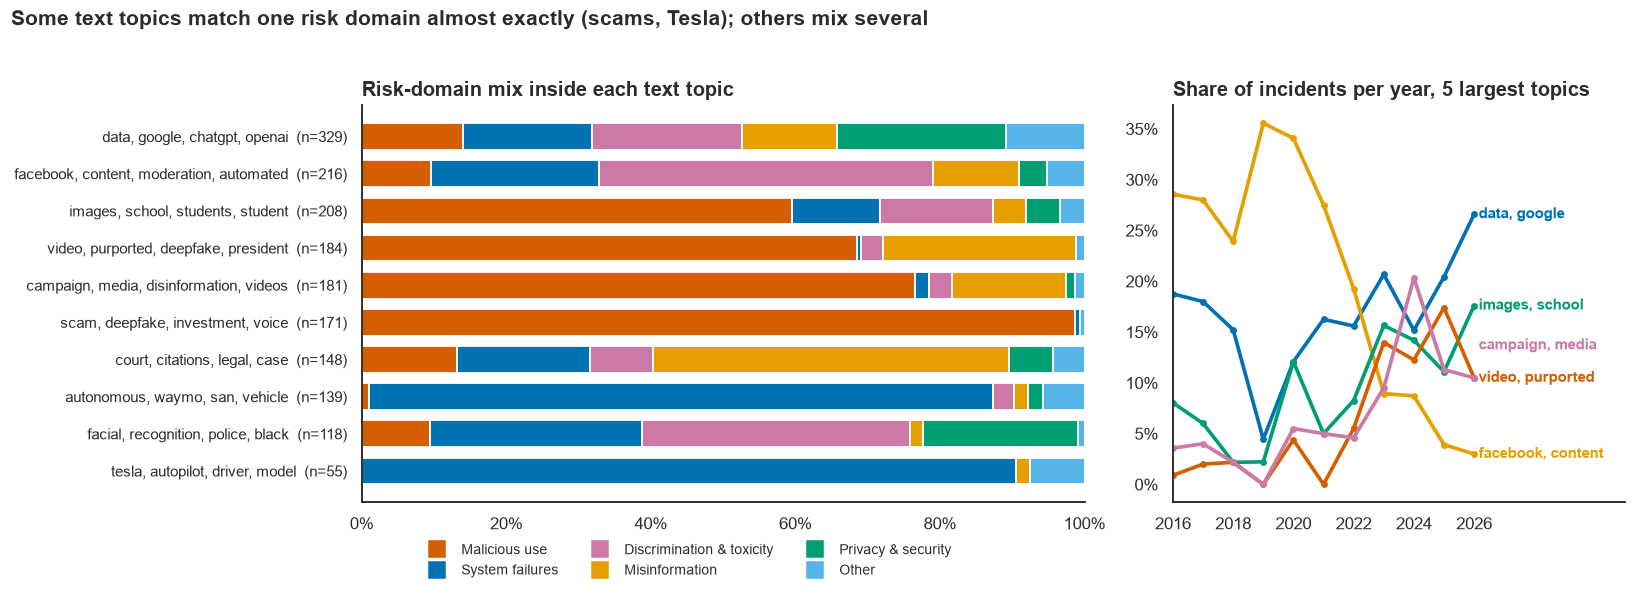

In [20]:
order = summary.sort_values("incidents", ascending=False).index.tolist()
share_dom = cls_only.div(cls_only.sum(1), axis=0).loc[order] * 100

fig, ax = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.6, 1]})
y = np.arange(len(order))[::-1]
left = np.zeros(len(order))
for d in DOMAINS:
    ax[0].barh(y, share_dom[d], left=left, color=DOM_COLOR[d], height=0.72, edgecolor="white", linewidth=1.2)
    left += share_dom[d].values
ax[0].set_yticks(y, [f"{topic_name[k]}  (n={tab.sum(1)[k]})" for k in order], fontsize=9.5)
ax[0].set_xlim(0, 100)
ax[0].xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax[0].set_title("Risk-domain mix inside each text topic")
domain_legend(ax[0], names=DOMAINS, loc="lower center", ncol=3, fontsize=9, bbox_to_anchor=(0.45, -0.22))

pt = pd.crosstab(inc.year.clip(lower=2016), inc.topic_nmf, normalize="index").loc[2016:] * 100
big = [k for k in order[:5]]
cols = sns.color_palette(["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7"])
ends = {k: pt[k].iloc[-1] for k in big}
ypos, last = {}, -99
for k in sorted(ends, key=ends.get):
    last = max(ends[k], last + 3.2)
    ypos[k] = last
for k, c in zip(big, cols):
    ax[1].plot(pt.index, pt[k], color=c, lw=2.4, marker="o", markersize=3.5)
    ax[1].text(pt.index[-1] + 0.15, ypos[k], ", ".join(topic_name[k].split(", ")[:2]), color=c, fontsize=9.5, fontweight="bold", va="center")
ax[1].set_xlim(2016, 2031)
ax[1].set_xticks(range(2016, 2027, 2))
ax[1].yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax[1].set_title("Share of incidents per year, 5 largest topics")
fig.suptitle("Some text topics match one risk domain almost exactly (scams, Tesla); others mix several",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.02)
fig.tight_layout()
save(fig, "14_nmf_topics")
plt.show()

### 8.3 Embeddings and clustering (BERTopic style)

Here every text is turned into a vector, reduced with UMAP and clustered with HDBSCAN, which finds the number of clusters itself and leaves unclear texts unassigned (noise). The clusters are named with *class-based TF-IDF*, as in BERTopic.

**Which embedding is used?** The cell below tries the sentence model `all-MiniLM-L6-v2` (install with `pip install sentence-transformers`; the model is downloaded on first use). If it is not available, it falls back to **LSA** (TF-IDF + SVD), a simpler embedding that runs anywhere. The notebook prints which one was used, and the rest of the code is the same.

In [21]:
def embed_texts(texts):
    try:
        from sentence_transformers import SentenceTransformer
        model = SentenceTransformer("all-MiniLM-L6-v2")
        return model.encode(texts, normalize_embeddings=True, show_progress_bar=False), "sentence-transformers (all-MiniLM-L6-v2)"
    except Exception as e:
        tf = TfidfVectorizer(stop_words=STOP, min_df=3, max_df=0.6, sublinear_tf=True, ngram_range=(1, 2))
        Z = TruncatedSVD(100, random_state=SEED).fit_transform(tf.fit_transform(texts))
        return normalize(Z), f"LSA fallback (TF-IDF + SVD), because sentence-transformers is not available ({type(e).__name__})"

E_inc, EMB_NAME = embed_texts(docs)
print("embedding used:", EMB_NAME, "| shape:", E_inc.shape)

xy = umap.UMAP(n_neighbors=15, min_dist=0.05, metric="cosine", random_state=SEED).fit_transform(E_inc)
z5 = umap.UMAP(n_neighbors=15, min_dist=0.0, n_components=5, metric="cosine", random_state=SEED).fit_transform(E_inc)
inc["cl"] = HDBSCAN(min_cluster_size=15, min_samples=5).fit_predict(z5)
inc["x"], inc["y"] = xy[:, 0], xy[:, 1]

def ctfidf_names(texts, labels, n=4):
    ids = sorted(set(labels) - {-1})
    joined = [" ".join(t for t, l in zip(texts, labels) if l == i) for i in ids]
    cvec = CountVectorizer(stop_words=STOP, min_df=2, ngram_range=(1, 1))
    Xc = cvec.fit_transform(joined).toarray().astype(float)
    tf_ = Xc / Xc.sum(1, keepdims=True)
    idf = np.log(1 + Xc.sum(1).mean() / Xc.sum(0))
    voc = np.array(cvec.get_feature_names_out())
    return {i: ", ".join(voc[np.argsort(-(tf_[k] * idf))[:n]]) for k, i in enumerate(ids)}

cl_name = ctfidf_names(docs, inc.cl.values)
n_cl = len(cl_name)
print(f"{n_cl} clusters found; {(inc.cl == -1).mean():.0%} of incidents left unassigned (noise)")

embedding used: LSA fallback (TF-IDF + SVD), because sentence-transformers is not available (ModuleNotFoundError) | shape: (1749, 100)
40 clusters found; 15% of incidents left unassigned (noise)


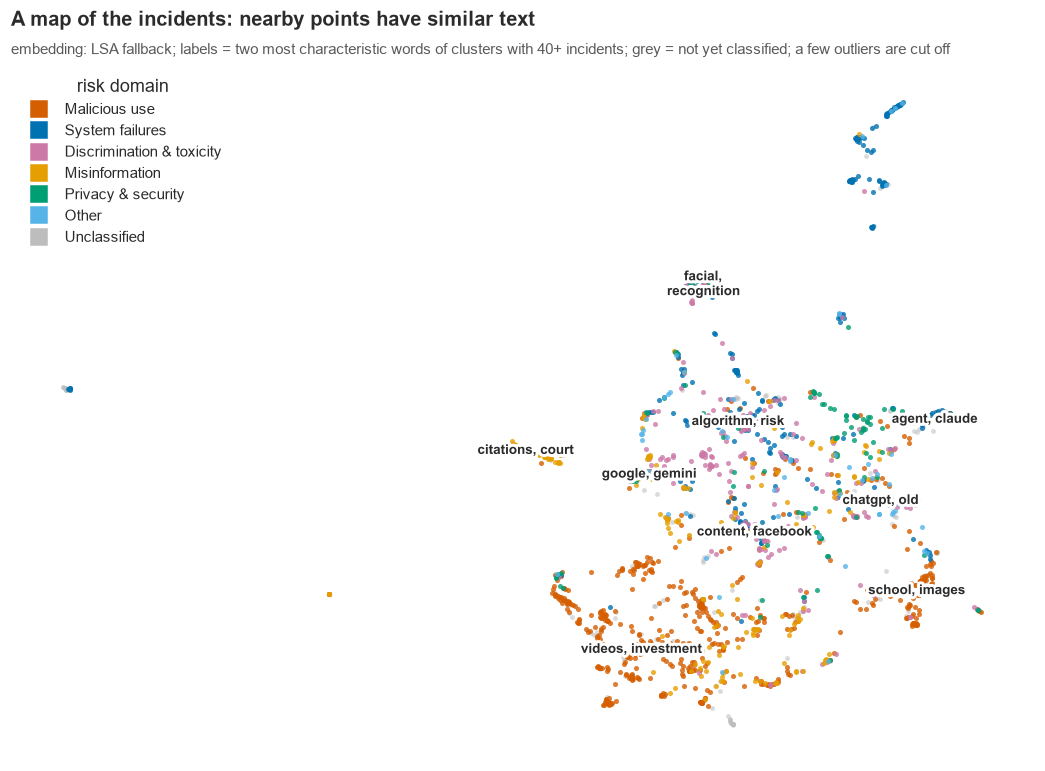

In [22]:
big_cl = inc[inc.cl >= 0].cl.value_counts()
big_cl = big_cl[big_cl >= 40].index

fig, ax = plt.subplots(figsize=(12, 8.2))
u = inc[~inc.classified]
ax.scatter(u.x, u.y, s=10, color=GREY, alpha=0.55, linewidths=0)
for d in DOMAINS:
    s_ = inc[inc.domain == d]
    ax.scatter(s_.x, s_.y, s=11, color=DOM_COLOR[d], alpha=0.8, linewidths=0)
for c in big_cl:
    s_ = inc[inc.cl == c]
    ax.annotate(textwrap.fill(", ".join(cl_name[c].split(", ")[:2]), 18), (s_.x.median(), s_.y.median()), ha="center", va="center", fontsize=8.8,
                fontweight="bold", path_effects=[pe.withStroke(linewidth=4, foreground="white")], zorder=5)
ax.set_xlim(*np.percentile(inc.x, [0.5, 99.5]) + np.array([-1, 1]))
ax.set_ylim(*np.percentile(inc.y, [0.5, 99.5]) + np.array([-1, 1]))
ax.axis("off")
domain_legend(ax, loc="upper left", fontsize=9.5, title="risk domain")
ax.set_title("A map of the incidents: nearby points have similar text")
subtitle(ax, f"embedding: {EMB_NAME.split(' (')[0]}; labels = two most characteristic words of clusters with 40+ incidents; grey = not yet classified; a few outliers are cut off")
ax.set_title(ax._left_title.get_text(), pad=26)
save(fig, "15_incident_map")
plt.show()

### 8.4 Comparing the three methods

,topics / clusters,incidents assigned,coherence (UMass),diversity,NMI with risk domain
NMF,10,100%,-81.512,0.94,0.255
LDA,10,100%,-102.775,0.87,0.242
Embedding + HDBSCAN (LSA fallback),40,85%,NaN,NaN,0.274


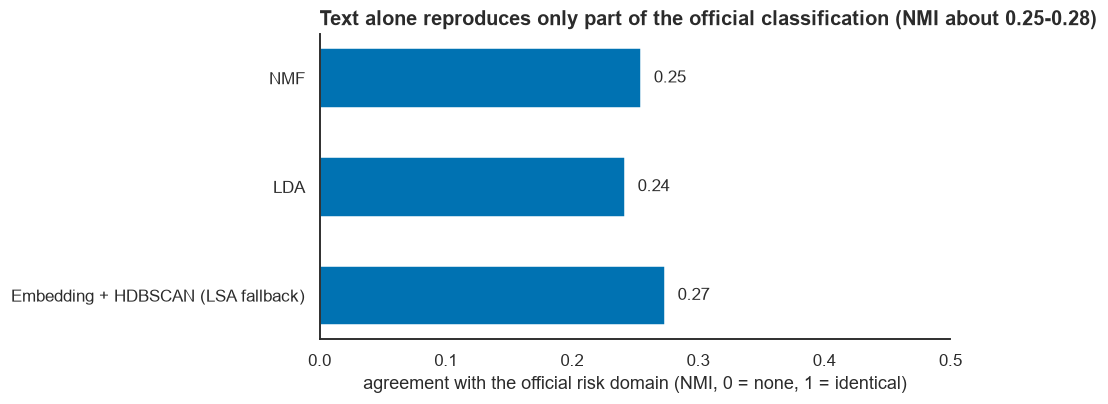

In [23]:
def nmi_domain(labels):
    m = inc.classified.values
    return normalized_mutual_info_score(inc.domain[m].astype(str), np.asarray(labels)[m])

lda = LatentDirichletAllocation(K_TOPICS, learning_method="batch", max_iter=25, random_state=SEED).fit(X_cnt)
inc["topic_lda"] = lda.transform(X_cnt).argmax(1)
assigned = inc.cl >= 0

comp = pd.DataFrame({
    "topics / clusters": [K_TOPICS, K_TOPICS, n_cl],
    "incidents assigned": ["100%", "100%", f"{assigned.mean():.0%}"],
    "coherence (UMass)": [umass(top_idx(nmf.components_), X_cnt), umass(top_idx(lda.components_), X_cnt), np.nan],
    "diversity": [diversity(top_idx(nmf.components_)), diversity(top_idx(lda.components_)), np.nan],
    "NMI with risk domain": [nmi_domain(inc.topic_nmf), nmi_domain(inc.topic_lda),
                              normalized_mutual_info_score(inc.domain[inc.classified & assigned].astype(str), inc.cl[inc.classified & assigned])],
}, index=["NMF", "LDA", f"Embedding + HDBSCAN ({EMB_NAME.split(' (')[0]})"])
display(comp.round(3))

fig, ax = plt.subplots(figsize=(7.4, 3.6))
v = comp["NMI with risk domain"]
ax.barh(v.index[::-1], v.values[::-1], color=BLUE, height=0.55)
for y, val in enumerate(v.values[::-1]):
    ax.text(val + 0.01, y, f"{val:.2f}", va="center", fontsize=11)
ax.set_xlim(0, max(v.max() * 1.2, 0.5))
ax.set_xlabel("agreement with the official risk domain (NMI, 0 = none, 1 = identical)")
ax.set_title("Text alone reproduces only part of the official classification (NMI about 0.25-0.28)")
save(fig, "16_method_comparison")
plt.show()

### 8.5 Topic modelling of the news reports

The same NMF is applied to the report titles (plus the description when present), English only, and compared across years. This shows what the media is writing about, independent of the incident database.

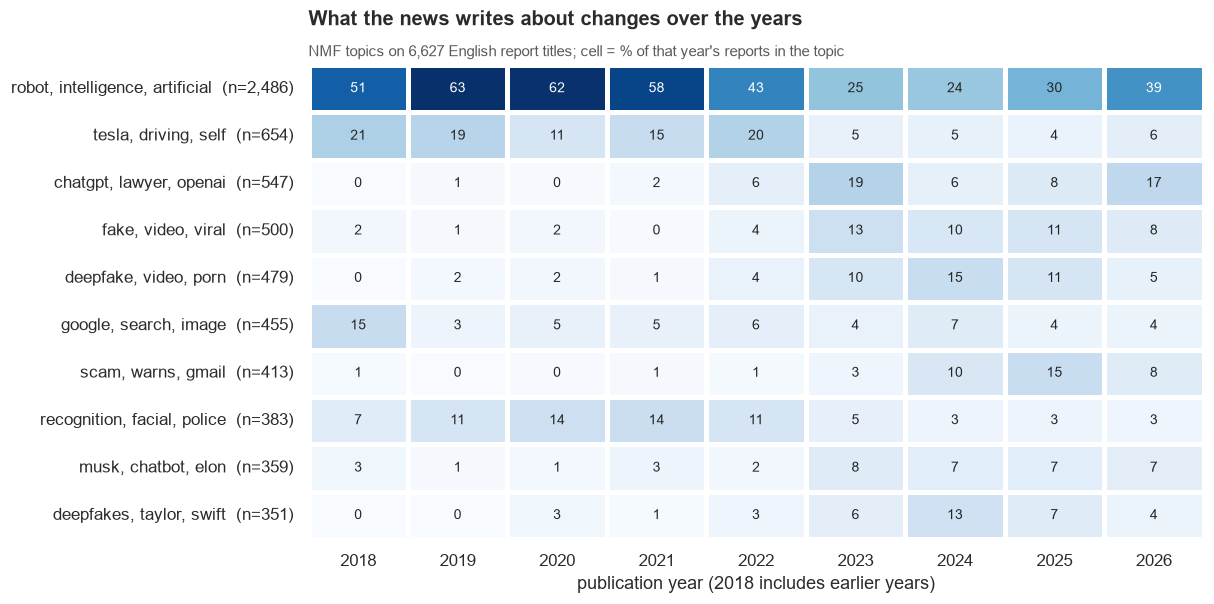

,top words,reports
7,"robot, intelligence, artificial, amazon, secur...",2486
1,"tesla, driving, self, crash, autopilot, car",654
3,"chatgpt, lawyer, openai, court, cases, shooting",547
6,"fake, video, viral, trump, images, obama",500
0,"deepfake, video, porn, videos, images, president",479
4,"google, search, image, black, gemini, results",455
8,"scam, warns, gmail, romance, investment, loses",413
2,"recognition, facial, police, technology, face,...",383
5,"musk, chatbot, elon, grok, hitler, antisemitic",359
9,"deepfakes, taylor, swift, election, explicit, ...",351


In [24]:
r_en = rep[(rep.Language == "en") & rep.text.str.len().gt(25)].drop_duplicates("Title").copy()
tf_r = TfidfVectorizer(stop_words=STOP + ["says", "say", "report", "reports", "news"], min_df=8, max_df=0.4, sublinear_tf=True)
X_r = tf_r.fit_transform(r_en.text)
voc_r = np.array(tf_r.get_feature_names_out())
K_R = 10
nmf_r = NMF(K_R, init="nndsvd", random_state=SEED, max_iter=400).fit(X_r)
r_en["topic"] = nmf_r.transform(X_r).argmax(1)
ti_r = top_idx(nmf_r.components_, 6)
name_r = {k: ", ".join(voc_r[ti_r[k][:3]]) for k in range(K_R)}

pt_r = pd.crosstab(r_en.topic, r_en.year.clip(lower=2018), normalize="columns") * 100
pt_r = pt_r.loc[:, 2018:2026]
size_r = r_en.topic.value_counts()
ordr = size_r.index.tolist()

fig, ax = plt.subplots(figsize=(10.5, 5.6))
sns.heatmap(pt_r.loc[ordr], annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax, linewidths=2, linecolor="white",
            yticklabels=[f"{name_r[k]}  (n={size_r[k]:,})" for k in ordr], annot_kws={"fontsize": 9})
ax.set_xlabel("publication year (2018 includes earlier years)")
ax.set_ylabel("")
ax.set_title("What the news writes about changes over the years")
subtitle(ax, f"NMF topics on {len(r_en):,} English report titles; cell = % of that year's reports in the topic", y=1.0)
ax.set_title(ax._left_title.get_text(), pad=26)
save(fig, "17_report_topics_by_year")
plt.show()
display(pd.DataFrame({"top words": [", ".join(voc_r[ti_r[k]]) for k in ordr], "reports": size_r[ordr].values}, index=ordr))

## 9. Can a model recognise the type of harm from the description?

**Task A (main): risk domain** (six classes, imbalanced: misuse is the largest). **Task B: intent** (intentional vs unintentional, balanced). Both use only the 1,490 classified incidents.

**Validation, in two ways.**
1. **Temporal split (our main result):** train on incidents up to 2024, test on the labelled incidents of 2025-26. This is the honest question: *would the model classify tomorrow's incidents?*
2. **Random 5-fold cross-validation:** the usual way. We show it next to the temporal result because it is usually more optimistic (similar incidents, such as the many deepfake cases, end up in both train and test).

**Models (No Free Lunch):** Complement Naive Bayes (a classic text baseline), logistic regression, random forest and XGBoost on TF-IDF features of title + description. Class imbalance is handled with class weights. The metric is **macro-F1** (every class counts equally); accuracy is also shown.

**Which information?** Text alone, entities alone (deployer, developer, harmed group, implicated systems), or both. Entities can be very informative (for example "Scammers" almost determines the domain), so this ablation shows how much the model needs the actual text.

In [25]:
lab = inc[inc.classified].copy()
y_dom_all = lab.domain.astype(str)
CLASSES = [d for d in DOMAINS if d in set(y_dom_all)]
cls_id = {c: i for i, c in enumerate(CLASSES)}

def split_pipe(s):
    return [t for t in s.split("|") if t]

def make_features(fit_df, other_dfs, use_text=True, use_ents=True):
    mats = []
    outs = [[] for _ in other_dfs]
    fit_parts = []
    if use_text:
        v = TfidfVectorizer(stop_words=STOP, min_df=3, max_df=0.7, ngram_range=(1, 2), sublinear_tf=True, max_features=6000)
        fit_parts.append(v.fit_transform(fit_df.text))
        for i, o in enumerate(other_dfs):
            outs[i].append(v.transform(o.text))
    if use_ents:
        v2 = CountVectorizer(tokenizer=split_pipe, lowercase=False, binary=True, min_df=3, token_pattern=None)
        fit_parts.append(v2.fit_transform(fit_df.ents))
        for i, o in enumerate(other_dfs):
            outs[i].append(v2.transform(o.ents))
    return sparse.hstack(fit_parts).tocsr(), [sparse.hstack(o).tocsr() for o in outs]

def new_model(name, n_classes):
    if name == "Naive Bayes":
        return ComplementNB(alpha=0.3)
    if name == "Logistic regression":
        return LogisticRegression(C=8, max_iter=2000, class_weight="balanced")
    if name == "Random forest":
        return RandomForestClassifier(300, min_samples_leaf=1, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
    if name == "XGBoost":
        kw = dict(n_estimators=250, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.5, n_jobs=-1, random_state=SEED)
        return XGBClassifier(objective="multi:softprob" if n_classes > 2 else "binary:logistic", **kw)

def fit_predict(name, Xtr, ytr, Xte, n_classes):
    m = new_model(name, n_classes)
    if name == "XGBoost":
        m.fit(Xtr, ytr, sample_weight=compute_sample_weight("balanced", ytr))
    else:
        m.fit(Xtr, ytr)
    return m, m.predict_proba(Xte)

MODELS = ["Naive Bayes", "Logistic regression", "Random forest", "XGBoost"]

def evaluate(df, y, use_text=True, use_ents=False, models=MODELS, cv=True):
    n_cl = len(np.unique(y))
    tr = (df.year <= 2024).values
    out = {}
    for name in models:
        Xtr, (Xte,) = make_features(df[tr], [df[~tr]], use_text, use_ents)
        m, p = fit_predict(name, Xtr, y[tr], Xte, n_cl)
        pred = p.argmax(1) if n_cl > 2 else (p[:, 1] > 0.5).astype(int) if p.ndim == 2 else (p > 0.5).astype(int)
        res = {"temporal macro-F1": f1_score(y[~tr], pred, average="macro"), "temporal accuracy": accuracy_score(y[~tr], pred)}
        if n_cl == 2:
            res["temporal AUC"] = roc_auc_score(y[~tr], p[:, 1])
        if cv:
            skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
            pr = np.zeros(len(y), int)
            for a, b in skf.split(df, y):
                Xa, (Xb,) = make_features(df.iloc[a], [df.iloc[b]], use_text, use_ents)
                _, pb = fit_predict(name, Xa, y[a], Xb, n_cl)
                pr[b] = pb.argmax(1)
            res["random-CV macro-F1"] = f1_score(y, pr, average="macro")
        out[name] = (res, p, tr)
    return out

y_dom = y_dom_all.map(cls_id).values
res_dom = evaluate(lab, y_dom, use_text=True, use_ents=False)
tab_dom = pd.DataFrame({k: v[0] for k, v in res_dom.items()}).T
n_test = int((lab.year >= 2025).sum())
print(f"train: {int((lab.year <= 2024).sum())} incidents (up to 2024), test: {n_test} incidents (2025-26)")
display(tab_dom.round(3))

train: 986 incidents (up to 2024), test: 510 incidents (2025-26)


,temporal macro-F1,temporal accuracy,random-CV macro-F1
Naive Bayes,0.532,0.722,0.629
Logistic regression,0.566,0.743,0.655
Random forest,0.472,0.680,0.587
XGBoost,0.463,0.673,0.567


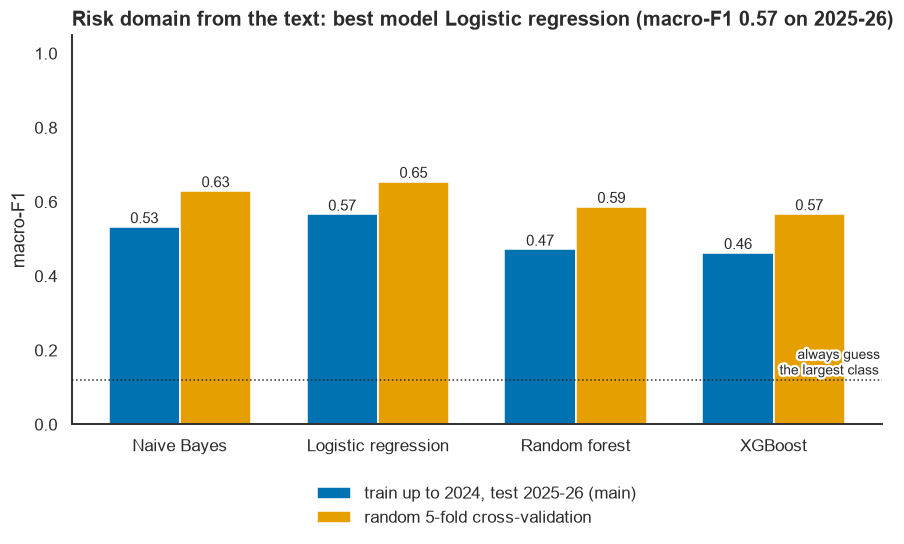

In [26]:
base_f1 = f1_score(y_dom[(lab.year >= 2025).values], np.full(n_test, np.bincount(y_dom).argmax()), average="macro")
fig, ax = plt.subplots(figsize=(9.5, 4.6))
x = np.arange(len(tab_dom)); w = 0.36
b1 = ax.bar(x - w / 2, tab_dom["temporal macro-F1"], w, color=BLUE, label="train up to 2024, test 2025-26 (main)")
b2 = ax.bar(x + w / 2, tab_dom["random-CV macro-F1"], w, color=ORANGE, label="random 5-fold cross-validation")
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.2f}", ha="center", fontsize=10)
ax.axhline(base_f1, color=INK, ls=":", lw=1)
ax.text(len(tab_dom) - 0.45, base_f1 + 0.015, "always guess\nthe largest class", ha="right", fontsize=9, path_effects=HALO)
ax.set_xticks(x, tab_dom.index)
ax.set_ylim(0, 1.05)
ax.set_ylabel("macro-F1")
ax.legend(loc="upper center", ncol=1, bbox_to_anchor=(0.5, -0.12))
best_dom = tab_dom["temporal macro-F1"].idxmax()
ax.set_title(f"Risk domain from the text: best model {best_dom} (macro-F1 {tab_dom['temporal macro-F1'].max():.2f} on 2025-26)")
save(fig, "18_domain_model_comparison")
plt.show()

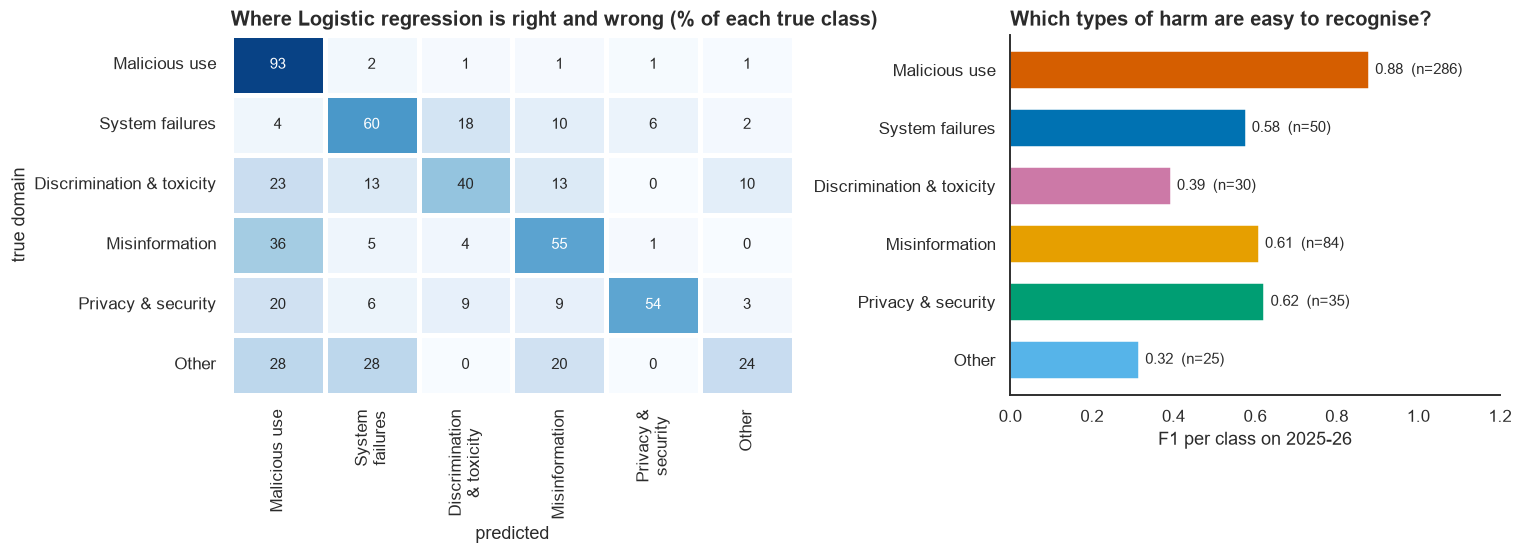

In [27]:
p_best = res_dom[best_dom][1]
te = ~res_dom[best_dom][2]
pred_best = p_best.argmax(1)
cm = confusion_matrix(y_dom[te], pred_best, normalize="true") * 100
f1c = f1_score(y_dom[te], pred_best, average=None)
sup = np.bincount(y_dom[te], minlength=len(CLASSES))

fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax[0], linewidths=2, linecolor="white",
            xticklabels=[textwrap.fill(c, 14) for c in CLASSES], yticklabels=CLASSES, annot_kws={"fontsize": 10})
ax[0].set_xlabel("predicted")
ax[0].set_ylabel("true domain")
ax[0].set_title(f"Where {best_dom} is right and wrong (% of each true class)")
yy = np.arange(len(CLASSES))[::-1]
ax[1].barh(yy, f1c, color=[DOM_COLOR[c] for c in CLASSES], height=0.65)
for y_, v, n in zip(yy, f1c, sup):
    ax[1].text(v + 0.015, y_, f"{v:.2f}  (n={n})", va="center", fontsize=10)
ax[1].set_yticks(yy, CLASSES)
ax[1].set_xlim(0, 1.2)
ax[1].set_xlabel("F1 per class on 2025-26")
ax[1].set_title("Which types of harm are easy to recognise?")
fig.tight_layout()
save(fig, "19_domain_confusion")
plt.show()

### 9.1 Which words and which information matter?

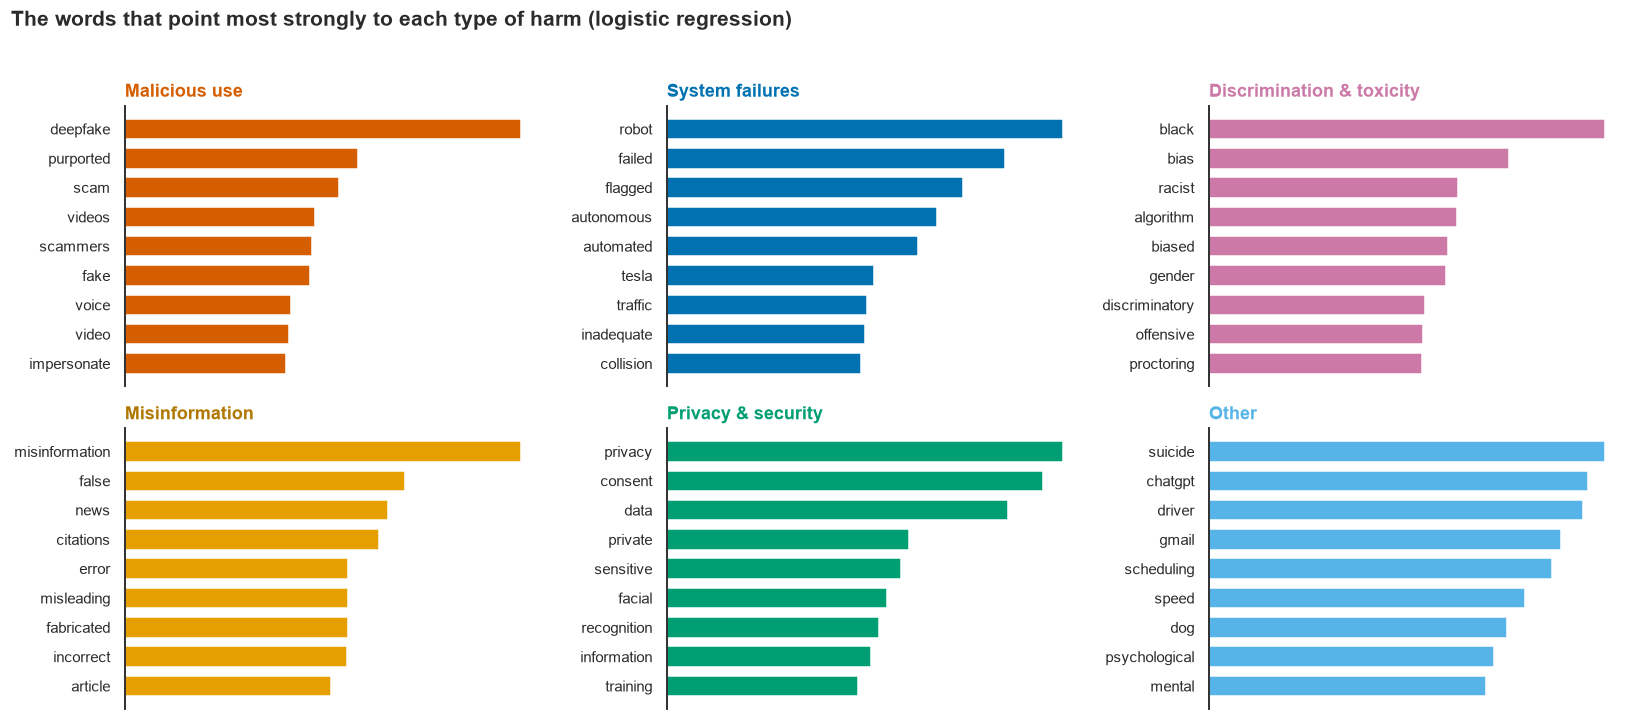

In [28]:
v_all = TfidfVectorizer(stop_words=STOP, min_df=3, max_df=0.7, ngram_range=(1, 2), sublinear_tf=True, max_features=6000)
Xa = v_all.fit_transform(lab.text)
lr = LogisticRegression(C=8, max_iter=2000, class_weight="balanced").fit(Xa, y_dom)
names = np.array(v_all.get_feature_names_out())

fig, axes = plt.subplots(2, 3, figsize=(15, 6.4))
for k, (axi, c) in enumerate(zip(axes.ravel(), CLASSES)):
    coef = lr.coef_[k]
    idx = np.argsort(-coef)[:9][::-1]
    axi.barh(names[idx], coef[idx], color=DOM_COLOR[c], height=0.7)
    axi.set_title(c, color=DOM_COLOR[c] if c != "Misinformation" else "#B07800", fontsize=11.5)
    axi.tick_params(axis="y", labelsize=9.5)
    axi.set_xticks([])
    axi.spines["bottom"].set_visible(False)
fig.suptitle("The words that point most strongly to each type of harm (logistic regression)", x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.02)
fig.tight_layout()
save(fig, "20_domain_top_words")
plt.show()

,text only,entities only,text + entities
Logistic regression,0.566,0.415,0.573
XGBoost,0.463,0.468,0.542


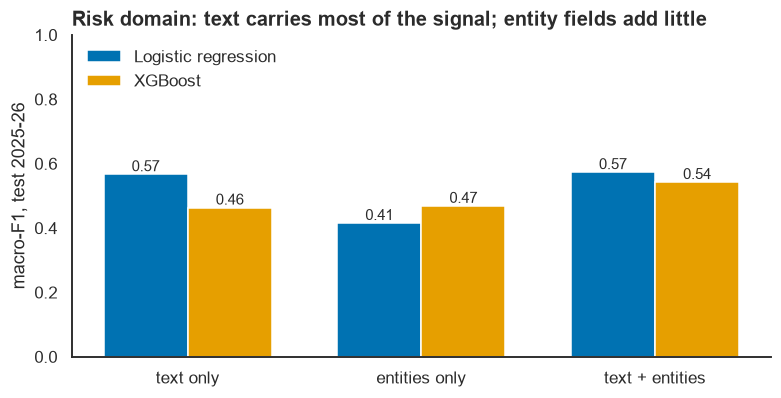

In [29]:
abl = {}
for label, ut, ue in [("text only", True, False), ("entities only", False, True), ("text + entities", True, True)]:
    r = evaluate(lab, y_dom, use_text=ut, use_ents=ue, models=["Logistic regression", "XGBoost"], cv=False)
    abl[label] = {m: r[m][0]["temporal macro-F1"] for m in r}
abl = pd.DataFrame(abl)
display(abl.round(3))

fig, ax = plt.subplots(figsize=(8.2, 3.8))
x = np.arange(len(abl.columns)); w = 0.36
for i, (m, col) in enumerate([("Logistic regression", BLUE), ("XGBoost", ORANGE)]):
    bars = ax.bar(x + (i - 0.5) * w, abl.loc[m], w, color=col, label=m)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.2f}", ha="center", fontsize=10)
ax.set_xticks(x, abl.columns)
ax.set_ylim(0, 1.0)
ax.set_ylabel("macro-F1, test 2025-26")
ax.legend(loc="upper left")
ax.set_title("Risk domain: text carries most of the signal; entity fields add little")
save(fig, "21_domain_ablation")
plt.show()

### 9.2 Task B: intent (intentional or accidental)

,temporal macro-F1,temporal accuracy,temporal AUC,random-CV macro-F1
Naive Bayes,0.849,0.866,0.936,0.846
Logistic regression,0.836,0.854,0.928,0.849
Random forest,0.853,0.864,0.928,0.846
XGBoost,0.786,0.808,0.894,0.836


AUC of logistic regression on 2025-26 by information used: {'text only': 0.928, 'entities only': 0.903, 'text + entities': 0.928}


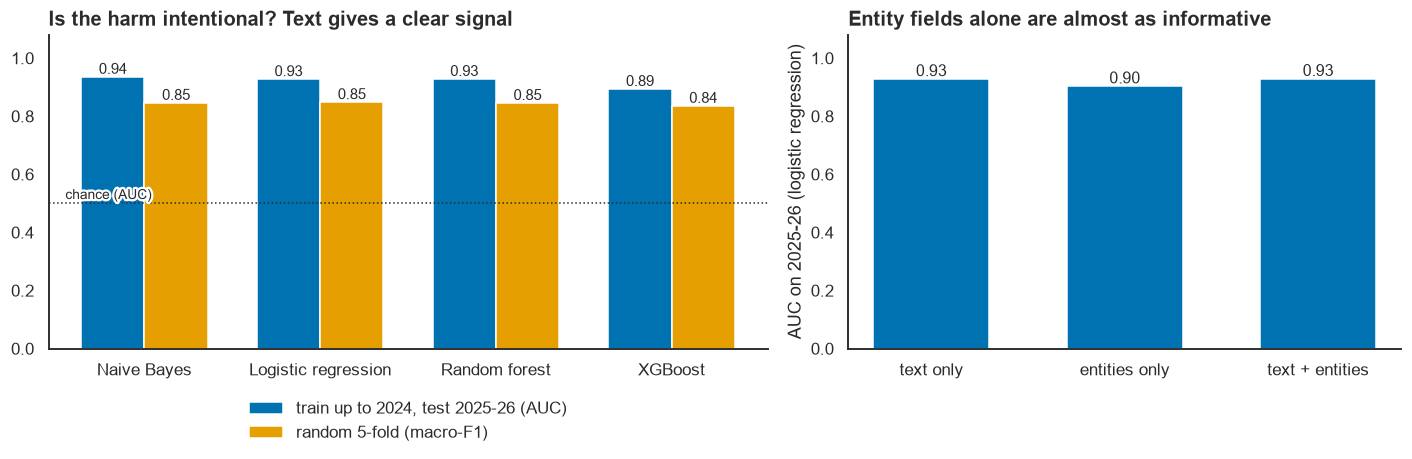

In [30]:
labi = inc[inc.intent_s.notna()].copy()
y_int = (labi.intent_s == "Intentional").astype(int).values
res_int = evaluate(labi, y_int, use_text=True, use_ents=False)
tab_int = pd.DataFrame({k: v[0] for k, v in res_int.items()}).T
display(tab_int.round(3))
r_ab = {}
for label, ut, ue in [("text only", True, False), ("entities only", False, True), ("text + entities", True, True)]:
    r = evaluate(labi, y_int, use_text=ut, use_ents=ue, models=["Logistic regression"], cv=False)
    r_ab[label] = r["Logistic regression"][0]["temporal AUC"]
print("AUC of logistic regression on 2025-26 by information used:", {k: round(v, 3) for k, v in r_ab.items()})

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
x = np.arange(len(tab_int)); w = 0.36
b1 = ax[0].bar(x - w / 2, tab_int["temporal AUC"], w, color=BLUE, label="train up to 2024, test 2025-26 (AUC)")
b2 = ax[0].bar(x + w / 2, tab_int["random-CV macro-F1"], w, color=ORANGE, label="random 5-fold (macro-F1)")
for b in list(b1) + list(b2):
    ax[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.2f}", ha="center", fontsize=10)
ax[0].axhline(0.5, color=INK, ls=":", lw=1)
ax[0].text(-0.45, 0.515, "chance (AUC)", ha="left", fontsize=9, path_effects=HALO)
ax[0].set_xticks(x, tab_int.index)
ax[0].set_ylim(0, 1.08)
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax[0].set_title("Is the harm intentional? Text gives a clear signal")
ra = pd.Series(r_ab)
ax[1].bar(ra.index, ra.values, color=BLUE, width=0.6)
for x_, v in enumerate(ra.values):
    ax[1].text(x_, v + 0.01, f"{v:.2f}", ha="center", fontsize=10.5)
ax[1].set_ylim(0, 1.08)
ax[1].set_ylabel("AUC on 2025-26 (logistic regression)")
ax[1].set_title("Entity fields alone are almost as informative")
fig.tight_layout()
save(fig, "22_intent_models")
plt.show()

## 10. The unclassified backlog: does it change the trend?

30% of the 2025-26 incidents have no risk domain yet. The main trend (section 4.2) uses only classified incidents. As a **robustness check** we let the best model predict the domain of the unclassified incidents and keep only **confident predictions** (probability of at least 0.6). The predicted share is shown with hatching, clearly separated from observed data. If the trend were an artefact of the backlog, adding the predictions would change it.

253 unclassified incidents; 129 predictions with confidence >= 0.6 (51%).


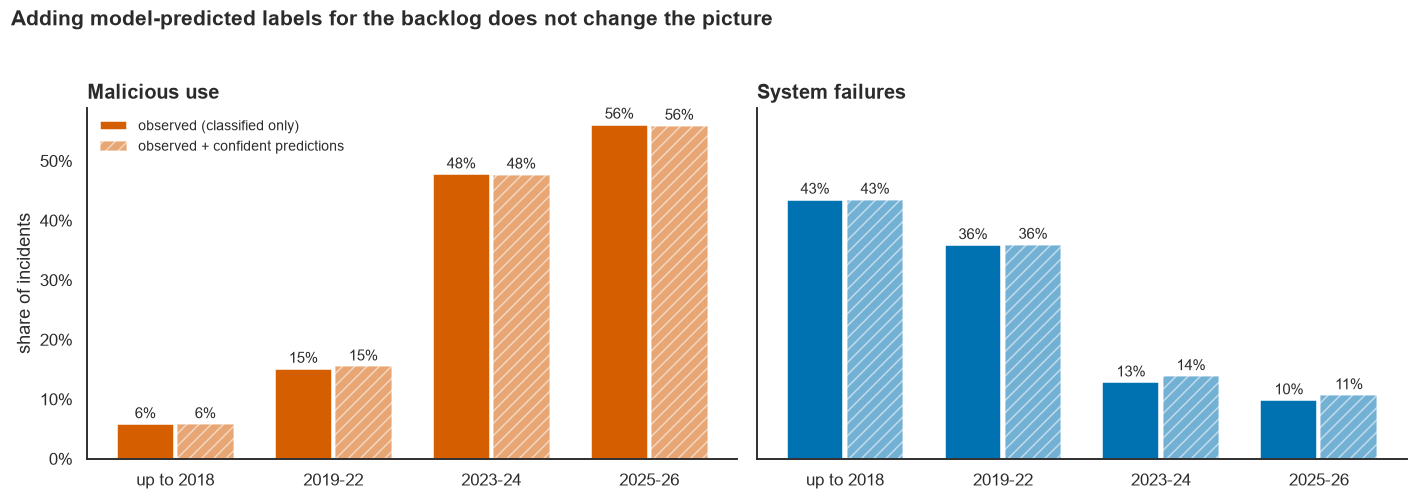

period,up to 2018,2019-22,2023-24,2025-26
observed,5.8,15.1,47.7,56.1
with predictions,5.8,15.5,47.7,55.9


In [31]:
CONF = 0.6
Xl, (Xu,) = make_features(lab, [inc[~inc.classified]], True, False)
m_final, pu = fit_predict("Logistic regression", Xl, y_dom, Xu, len(CLASSES))
unc = inc[~inc.classified].copy()
unc["pred"] = [CLASSES[i] for i in pu.argmax(1)]
unc["conf"] = pu.max(1)
keep = unc[unc.conf >= CONF]
print(f"{len(unc)} unclassified incidents; {len(keep)} predictions with confidence >= {CONF} ({len(keep) / len(unc):.0%}).")

obs = pd.crosstab(inc.period, inc.domain).reindex(columns=DOMAINS)
prd = pd.crosstab(keep.period, keep.pred).reindex(index=obs.index, columns=DOMAINS, fill_value=0)
mis_obs = obs["Malicious use"] / obs.sum(1) * 100
mis_all = (obs["Malicious use"] + prd["Malicious use"]) / (obs.sum(1) + prd.sum(1)) * 100
fail_obs = obs["System failures"] / obs.sum(1) * 100
fail_all = (obs["System failures"] + prd["System failures"]) / (obs.sum(1) + prd.sum(1)) * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for axi, o, a, d, ttl in [(ax[0], mis_obs, mis_all, "Malicious use", "Malicious use"), (ax[1], fail_obs, fail_all, "System failures", "System failures")]:
    x = np.arange(len(o))
    axi.bar(x - 0.19, o.values, 0.36, color=DOM_COLOR[d], label="observed (classified only)")
    axi.bar(x + 0.19, a.values, 0.36, color=DOM_COLOR[d], alpha=0.55, hatch="///", edgecolor="white", label="observed + confident predictions")
    for xi, vo, va in zip(x, o.values, a.values):
        axi.text(xi - 0.19, vo + 1, f"{vo:.0f}%", ha="center", fontsize=9.5)
        axi.text(xi + 0.19, va + 1, f"{va:.0f}%", ha="center", fontsize=9.5)
    axi.set_xticks(x, o.index)
    axi.set_title(ttl)
ax[0].yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax[0].set_ylabel("share of incidents")
ax[0].legend(loc="upper left", fontsize=9)
fig.suptitle("Adding model-predicted labels for the backlog does not change the picture", x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.03)
fig.tight_layout()
save(fig, "23_backlog_robustness")
plt.show()
display(pd.DataFrame({"observed": mis_obs, "with predictions": mis_all}).round(1).T)

## 11. Hypotheses and effect sizes

We state the hypotheses and report the **size of the change with a 95% interval**, not only a p-value. The comparison is between the periods `2019-22` and `2025-26` (classified incidents only). Percentage points (pp) are the difference between the two shares. The intervals use a bootstrap of incidents; they ignore that the database selects what is reported, so they describe the data we have, not all AI harm.

* **H1.** Malicious use became a larger share of incidents.
* **H2.** The share of intentional harm increased.
* **H3.** System failures became a smaller share.
* **H4.** The amount of media coverage per incident depends only weakly on the type of harm (tested in section 6.1, effect size epsilon-squared).

,hypothesis,2019-22,2025-26,change (pp),lo,hi,n
0,H1 Malicious use share,15.1,56.1,41.0,35.1,46.8,318 vs 510
1,H2 Intentional harm share,29.9,63.7,33.7,27.1,40.4,314 vs 501
2,H3 System failures share,35.8,9.8,-26.0,-32.2,-20.2,318 vs 510


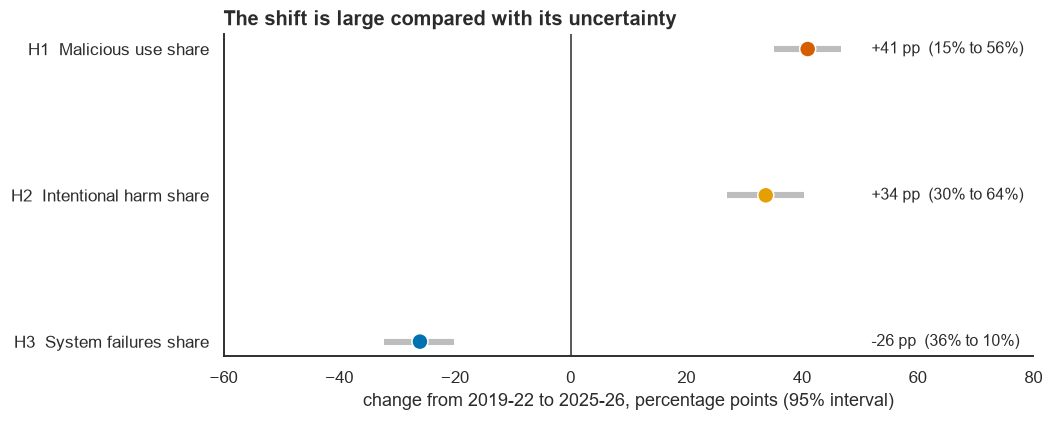

In [32]:
def boot_diff(flag, mask, p1="2019-22", p2="2025-26", n=3000):
    a = flag[(inc.period == p1) & mask].dropna().values
    b = flag[(inc.period == p2) & mask].dropna().values
    d = [rng.choice(b, len(b)).mean() - rng.choice(a, len(a)).mean() for _ in range(n)]
    return (b.mean() - a.mean()) * 100, np.percentile(d, [2.5, 97.5]) * 100, a.mean() * 100, b.mean() * 100, len(a), len(b)

inc["is_failure"] = (inc.domain == "System failures").astype(float).where(inc.classified)
tests = [("H1  Malicious use share", inc.is_misuse, inc.classified),
         ("H2  Intentional harm share", inc.is_intentional, inc.intent_s.notna()),
         ("H3  System failures share", inc.is_failure, inc.classified)]
rows = []
for name, flag, mask in tests:
    d, (lo, hi), s1, s2, n1, n2 = boot_diff(flag, mask)
    rows.append({"hypothesis": name, "2019-22": s1, "2025-26": s2, "change (pp)": d, "lo": lo, "hi": hi, "n": f"{n1} vs {n2}"})
hyp = pd.DataFrame(rows)
display(hyp.round(1))

fig, ax = plt.subplots(figsize=(9.5, 3.8))
yy = np.arange(len(hyp))[::-1]
ax.hlines(yy, hyp.lo, hyp.hi, color=GREY, lw=4)
ax.scatter(hyp["change (pp)"], yy, s=110, color=[DOM_COLOR["Malicious use"], ORANGE, DOM_COLOR["System failures"]], zorder=3, edgecolor="white")
for y_, r in zip(yy, hyp.itertuples()):
    ax.text(52, y_, f"{r._4:+.0f} pp  ({r._2:.0f}% to {r._3:.0f}%)", va="center", fontsize=10.5)
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(yy, hyp.hypothesis)
ax.set_xlim(-60, 80)
ax.set_xlabel("change from 2019-22 to 2025-26, percentage points (95% interval)")
ax.set_title("The shift is large compared with its uncertainty")
save(fig, "24_effect_sizes")
plt.show()

## 12. Interactive map
Hover over a point for title, year and domain; click a domain in the legend to hide or show it.

In [33]:
fig = go.Figure()
for d in DOMAINS + ["Unclassified"]:
    s = inc[inc.dom_label == d]
    fig.add_trace(go.Scattergl(x=s.x, y=s.y, mode="markers", name=f"{d} ({len(s)})",
                               marker=dict(size=6, color=DOM_COLOR[d], opacity=0.8),
                               text=[f"{t}<br>{int(y_)} | {d}" for t, y_ in zip(s.title.str.slice(0, 90), s.year)], hoverinfo="text"))
fig.update_layout(template="simple_white", height=640, width=980, title="Map of AI incidents (text similarity)",
                  xaxis=dict(visible=False), yaxis=dict(visible=False), legend_title="risk domain")
fig.write_html(FIG_DIR / "25_interactive_map.html")
show_plotly(fig)

## 13. Conclusions

All numbers below come from this snapshot (19 Oct 2026). 2026 is a partial year.

**1. The mix of harm changed a lot.** Among classified incidents, *malicious use* grew from 15% (2019-22) to 56% (2025-26), +41 percentage points (95% interval +35 to +47). *System failures* fell from 36% to 10% (-26 pp, -32 to -20). The share of *intentional* harm rose from 30% to 64% (+34 pp, +27 to +40). Fraud and scams are the largest single subdomain in 2025-26 (45% of classified incidents, against 3% up to 2018). The picture is the same when the unclassified backlog is filled with confident model predictions (changes of about 1 pp or less, figure 23).

**2. The people and tools behind it.** The most frequent deployers are *Scammers* (238 incidents) and *Deepfake Creators* (124); the most frequent developer entries are generic tool categories (*deepfake*, *synthetic audio* developers). Large platforms (Meta, OpenAI, Google) mostly appear with their own systems and with a mix of harm types, not with a single one.

**3. The media lens.** Report volume per year grew from 126 (2019) to 1,520 (2025). Coverage is concentrated in a few outlets (10 of 2,177 source domains hold 19% of reports) and one submitter contributed about half of all reports in the database. In titles, self-driving cars dominated early, chatbots/LLMs rise sharply in 2023 and deepfakes/scams peak in 2024. The number of reports per incident is low for every type of harm (median 2); the type of harm explains very little of the differences (epsilon-squared 0.02).

**4. Topic models.** NMF gave more coherent and more distinct topics than LDA at every number of topics (for 10 topics: coherence -82 vs -103, diversity 0.94 vs 0.87). Some topics match one risk domain almost exactly (scams: 99% malicious use; Tesla/autopilot: 91% system failures); others mix several (for example data/privacy). Overall the text topics reproduce only a part of the official classification (NMI 0.24 to 0.28 for the three methods); the embedding + HDBSCAN version (here the LSA fallback) is only slightly higher than NMF, and it leaves 14% of incidents unassigned. No method is best on every criterion.

**5. Classification.** On the honest test (train up to 2024, test 2025-26) risk domain is recognised with macro-F1 0.57 (logistic regression; accuracy 0.74), clearly above guessing the largest class (about 0.12), and above Naive Bayes 0.53, random forest 0.47, XGBoost 0.44. Random cross-validation is more optimistic for every model (0.56 to 0.65), as expected with many near-duplicate incidents. Malicious use is easy (F1 0.88); discrimination (0.39) and "other" (0.32) are hard, and many misinformation and discrimination cases are predicted as malicious use. Adding entity fields (deployer, developer, harmed, systems) did not improve logistic regression (0.57 vs 0.57) but helped XGBoost (0.44 to 0.54). *Intent* is much easier: AUC 0.93 to 0.94 for the three best models on 2025-26 (entity fields alone reach 0.90).

**Limitations.**
* The AIID is not a census: it reflects what is reported, submitted and edited. Growth in incidents and reports is partly growth in attention and curation, and one submitter dominates the reports.
* 30% of the 2025-26 incidents have no risk domain yet; we only use the classified ones (and a robustness check with predictions).
* The labels were assigned by the taxonomy authors; we do not know how consistent they are, so classification accuracy is measured against these labels, not against the truth. Some labels may have been assisted by language models (not verified).
* Reports cannot be linked to incidents, so we cannot study reporting delay or the coverage of a given incident over time.
* The technical (GMF) and policy (CSET) layers cover only 1% and 12% of incidents, so we cannot say anything about technical causes.
* The sentence-embedding option was not tested by the author of this notebook in the environment where it was built (no model download possible); the results shown use the LSA fallback. Run it on your machine after `pip install sentence-transformers` and check that the clusters are still sensible.
* Hypothesis intervals describe sampling uncertainty only, not selection bias.

**Take-home message.** In this database the typical AI incident moved from *a system that fails* to *a person who uses AI to deceive*, and the words in a short description are enough to recognise this shift and, to a good degree, the type of harm.


## 14. Suggested 20-minute storyboard

| min | Message | Figures |
|---|---|---|
| 0-2 | Hook: one of the most-reported incidents and the question | `10_top_incidents_timeline` |
| 2-4 | The data and its limits (a curated database, not a census) | `01_coverage`, `02_incidents_per_year` |
| 4-9 | The shift from AI that breaks to AI that is weaponised | `03_domains_over_time`, `04_intent_misuse_trend`, `05_subdomain_heatmap` |
| 9-11 | Who is involved | `06_deployers_developers`, `07_deployer_developer_links` |
| 11-13 | The media lens | `11_reports_volume_sources`, `12_media_themes` |
| 13-16 | Topic modelling and the map of incidents | `13_topic_number_sweep`, `14_nmf_topics`, `15_incident_map`, `16_method_comparison` |
| 16-18 | Can a model recognise the harm? | `18_domain_model_comparison`, `19_domain_confusion`, `21_domain_ablation` |
| 18-20 | Robustness, effect sizes, limitations | `23_backlog_robustness`, `24_effect_sizes` |